## Abstract and Introduction

### Abstract

This project addresses early capacity prediction for Ni-MH cells in a private battery-testing lab. The operational problem is straightforward: each cell needs a full galvanostatic discharge of up to 14 hours before a pass/fail decision can be made, plus up to 72 hours of deep reconditioning when needed. The goal is to predict $C_{\mathrm{final}}$ from the first 60–150 minutes of the discharge curve and issue an early decision without waiting for the full test.

We frame this as two parallel tasks: (1) binary classification (PASS if $C_{\mathrm{final}} \geq 5.0$ Ah) and (2) continuous capacity regression. For classical ML we extract 12 scalar features per observation window (derivatives, boundary values, mean/std of V and C) and evaluate Logistic Regression, Random Forest, SVM, XGBoost, and MLP over 10 windows from 30 to 300 minutes. For deep learning we feed 4-channel raw tensors ($V$, $C$, $\dot{V}$, $\dot{C}$, shape $151 \times 4$) into an LSTM and a 1D-CNN, using 8-fold Group K-Fold CV.

Results: the 1D-CNN outperforms the LSTM on this ~70-cell dataset, consistent with LSTMs needing more data to generalize. SVR is the most stable regression baseline among classical models. Gaussian noise augmentation (3 noisy copies per training fold, 4× total) reduces the generalization gap for the 1D-CNN. Across all models, a 90-minute observation window captures most of the predictable information — roughly 10% of the full test cycle.


### Introduction

Each used battery cell tested in this facility occupies a test station for up to 14 hours during a full discharge. If it fails and needs deep reconditioning (voltage-depression recovery), the total cycle can reach 72–90 hours. With dozens of cells tested in parallel, station throughput is a real constraint.

The core question: **can we predict a cell's final discharge capacity from the first 60–150 minutes of its discharge curve?** A reliable early predictor allows cutting the test short as soon as enough data is available, freeing up stations for other cells.

#### Project Objectives

1. **Early prediction feasibility**: test whether observation windows from 30 to 300 minutes (10 steps of 30 minutes each) contain enough information to classify or estimate $C_{\mathrm{final}}$.
2. **Feature engineering vs. raw signal**: compare hand-crafted features (classical ML) against end-to-end learning on raw sequences (deep learning).
3. **Classification vs. regression**: determine whether a direct binary classifier or a thresholded capacity regressor gives a better operational decision.

#### Notebook Structure

1. **Abstract and Introduction**: problem definition and project overview.
2. **Library Configuration and Data Loading**: imports, CSV ingestion, 10-second resampling, 80/20 train/Test split.
3. **Binary Classification**: 12-feature extraction, 5-model ROC-AUC sweep over 10 time windows, `GridSearchCV` tuning on the `[60, 90]` min window, Test evaluation with confusion matrices, learning curves.
4. **Regression**: 28-feature lagged extraction (4 blocks × 7 features), 3-model tuning over `{60, 90, 120, 150}` min with early-prediction preference ($\varepsilon = 0.025$ Ah), Test scatter plots.
5. **Deep Learning**: 4-channel tensors ($151 \times 4$), 8-fold Group CV for LSTM and 1D-CNN, then a repeat with Gaussian noise augmentation (4× training data).


### Physical Context: The Ni-MH Flat Plateau

Ni-MH cells behave differently from Li-ion: the discharge voltage stays nearly flat at ~1.2 V for roughly 80% of the cycle due to the dual-phase hydrogen insertion/extraction in the metal-hydride electrode. Only in the last ~20% does it drop sharply ("the knee"). This makes early-stage prediction harder, during the first 60–150 minutes, absolute voltage variation is small and partly masked by sensor noise.

This constraint motivates including $\dot{V} = \Delta V / \Delta t$ alongside the raw voltage: the slope of the plateau, even when tiny, correlates with the cell's state of health. The same reasoning drives the use of $\dot{C}$ as a channel in the deep learning models.

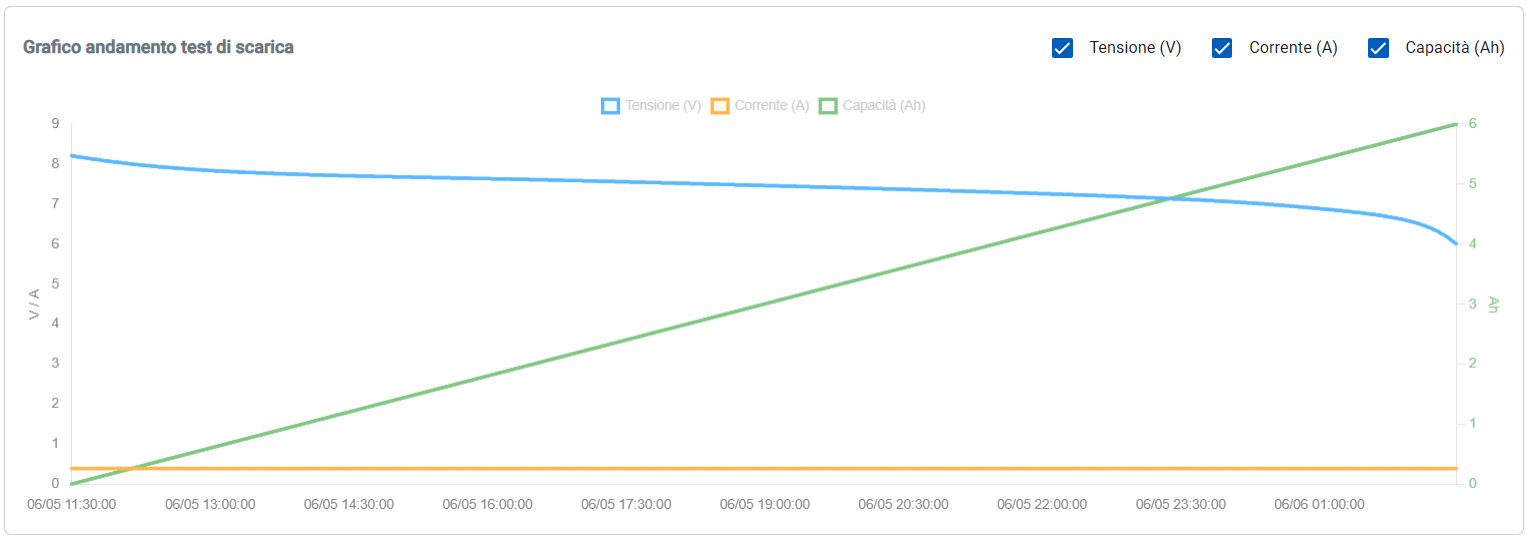


## Problem Formulation

### Dataset and Signal

Given $N$ independent discharge tests. Each test $\mathcal{S}_i$ is a multivariate time series sampled at uniform steps:

$$\mathcal{S}_i = \left\{ (V_{t,i},\; I_{t,i},\; C_{t,i}) \right\}_{t=1}^{T_i}$$

where $V$ is terminal voltage (V), $I$ is discharge current (A), and $C$ is cumulative capacity (Ah). The regression target is the total capacity at end of discharge:

$$C_{\mathrm{final}, i} = \max_t C_{t,i} = \sum_{t=1}^{T_i} I_{t,i} \cdot \Delta t$$

In this dataset the discharge current $I$ is practically constant (galvanostatic test), so the two informative channels are effectively $V$ and $C$.

### Two Prediction Tasks

**Classification.** The binary label is assigned by thresholding:
$$y_i = \mathbb{I}(C_{\mathrm{final}, i} \ge C_{\min}), \qquad C_{\min} = 5.0 \text{ Ah}$$
Classifiers predict $y_i$ directly, optimizing binary cross-entropy.

**Regression.** The continuous value $\hat{C}_{\mathrm{final}, i}$ is estimated by minimizing MSE. A binary decision can then be recovered post-hoc:
$$\hat{y}_i = \mathbb{I}(\hat{C}_{\mathrm{final}, i} \ge C_{\min})$$

Comparing these two approaches directly answers Objective 3: does optimizing over the full continuous target produce a better binary classifier than training the decision boundary directly?


### Partial Observation Constraint

Each model only sees the first $W$ minutes of the discharge. All data after minute $W$ is hidden:
$$\mathbf{X}_{\text{input}, i} = \{\mathbf{x}_{t,i}\}_{t=1}^{W}$$

The two functions to learn are:
$$f_{\text{class}}: \mathbb{R}^{W \times 3} \to \{0, 1\}, \qquad f_{\text{reg}}: \mathbb{R}^{W \times 3} \to \mathbb{R}^+$$

No future information ($t > W$) can enter the pipeline, not in feature computation, not in scaling, and not in label generation.


## Evaluation Metrics

To evaluate the goodness of the models, based on the different tasks, different metrics are used.

### Classification Metrics

Applied to Task 1 models and to thresholded regression outputs.

**Accuracy:** is the proportion of correct predictions a model makes out of the total predictions.
$$\text{Accuracy} = \frac{1}{N} \sum_{i=1}^{N} \mathbb{I}(Y_i = \hat{Y}_i)$$

**Precision**: certifying a degraded cell as PASS (False Positive) is the costliest error in this context:
$$\text{Precision} = \frac{TP}{TP + FP}$$

**Recall**: is the proportion of actual positive cases that the model successfully identifies.
$$\text{Recall} = \frac{TP}{TP + FN}$$

**ROC-AUC**: the primary metric throughout the temporal sweep and hyperparameter search. It is threshold-agnostic, so it allows comparing models at all possible operating points.

### Regression Metrics

The following metrics are applied to regression models, to evaluate the quality of the continuous predictions $\hat{C}_{\mathrm{final}, i}$.

**MSE (Mean Squared Error)**: quadratic, weights large errors more heavily:
$$\text{MSE} = \frac{1}{N} \sum_{i=1}^{N} (C_{\mathrm{final}, i} - \hat{C}_{\mathrm{final}, i})^2$$

**MAE (Mean Absolute Error)**: average error in Ah, directly interpretable operationally:
$$\text{MAE} = \frac{1}{N} \sum_{i=1}^{N} |C_{\mathrm{final}, i} - \hat{C}_{\mathrm{final}, i}|$$

**$R^2$ (Coefficient of Determination)**: fraction of capacity variance explained by the model:
$$R^2 = 1 - \frac{\sum_{i} (C_{\mathrm{final}, i} - \hat{C}_{\mathrm{final}, i})^2}{\sum_{i} (C_{\mathrm{final}, i} - \bar{C}_{\mathrm{final}})^2}$$


## Library Configuration and Data Loading

### Imports

All imports are in one cell so any missing package is caught immediately.

| Area | Libraries |
|---|---|
| Data | `pandas`, `numpy`, `os`, `glob` |
| Visualization | `matplotlib` |
| Classical ML | `scikit-learn`, `xgboost` |
| Reproducibility | `RANDOM_SEED = 42` |

`RANDOM_SEED = 42` is passed to every stochastic object (`train_test_split`, all estimators, `np.random.seed`). All results in this notebook are fully reproducible.


In [1]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split,GroupKFold, StratifiedGroupKFold, GridSearchCV,learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, make_scorer, roc_auc_score, mean_absolute_error, r2_score, mean_squared_error
from sklearn.svm import SVC, SVR
from sklearn.calibration import CalibratedClassifierCV
from xgboost import XGBClassifier, XGBRegressor
from sklearn.neural_network import MLPClassifier



RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

### Data Loading and Temporal Resampling

Each battery test is stored as a separate CSV file (`;`-separated). The loader `load_and_resample_battery_csv` does three minor tasks to prepare the data for modeling:

1. **Parses `Tempo`** and sorts rows chronologically.
2. **Computes `elapsed_min`**: minutes elapsed since the start of that test, reset to 0 per file.
3. **Downsamples to 10-second resolution** (`resample_sec=10`): groups rows by 10-second windows and takes the column mean.

The 10-second downsampling matters for two reasons: it reduces high-frequency sensor noise, and it gives all files the same temporal grid, which is a prerequisite for computing $\Delta V / \Delta t$ with a consistent denominator across tests.

All loaded DataFrames go into `battery_dict`, keyed by filename.


In [2]:
def load_and_resample_battery_csv(file_path, resample_sec=10):
    """
    Reads a single telemetry CSV file, calculates elapsed time, and applies temporal
    downsampling based on a window of seconds (resample_sec).
    """
    # 1. Load the CSV file with the correct separator
    df = pd.read_csv(file_path, sep=';')
    
    # 2. Sequential sorting of the DataFrame based on the 'Tempo' column
    df['Tempo'] = pd.to_datetime(df['Tempo'], utc=True)
    df = df.sort_values('Tempo').reset_index(drop=True)
    
    # 3. Immediate calculation of the native time column (elapsed_min)
    # Indicates how many minutes have passed since the exact start of the test for this specific cell
    df['elapsed_min'] = (df['Tempo'] - df['Tempo'].iloc[0]).dt.total_seconds() / 60.0
    
    # 4. APPLYING DOWNSAMPLING (If requested)
    if resample_sec is not None and resample_sec > 1:
        # Set the timestamp as the temporal index to use Pandas' resample functions
        df = df.set_index('Tempo')
        
        # Aggregate by taking the mean of the physical values in the chosen second window
        df_resampled = df.resample(f'{resample_sec}s').mean()
        
        # Restore the index and correctly recalculate the elapsed time column
        df = df_resampled.reset_index()
        df['elapsed_min'] = (df['Tempo'] - df['Tempo'].iloc[0]).dt.total_seconds() / 60.0
        
    return df

In [3]:
RAW_CSV_FOLDER = "data\\raw_csvs"

csv_files = sorted(glob.glob(os.path.join(RAW_CSV_FOLDER, "*.csv")))

battery_dict = {}

for file_path in csv_files:
    file_name = os.path.basename(file_path)
    df_clean = load_and_resample_battery_csv(file_path, resample_sec=10)
    if df_clean is not None and len(df_clean) > 0:
        battery_dict[file_name] = df_clean


### Train/Test Split

File list is splitted, not individual rows, into 80% train/validation and 20% Test **before any feature extraction**. Splitting after feature extraction would let the scaler or any other statistic estimated on all files bleed into the test set.

The split is at the **file level**: all feature vectors from a given battery file go to either train or Test, never both. This group isolation is enforced here by `train_test_split` on the file list, and later by `GroupKFold`/`StratifiedGroupKFold` inside cross-validation.

`file_Test_test` is sealed here and only accessed in the final evaluation cell of each task.


In [4]:
list_unique_files = list(battery_dict.keys())

file_train_val, file_Test_test = train_test_split(
    list_unique_files, 
    test_size=0.20, 
    random_state=RANDOM_SEED,
    shuffle=True
)

# Binary Early Classification (PASS/FAIL)

Each capacity test is assigned a binary label according to the following rule:

$$y_i = \mathbb{I}(C_{\mathrm{final}, i} \ge 5.0 \text{ Ah})$$

A cell delivering $\geq 5.0$ Ah is **1 (PASS)**; below that it is **0 (FAIL)**. The 5.0 Ah threshold is the rated nominal capacity of these Ni-MH cells, cells below it are candidates for deep reconditioning.

Two summary DataFrames are built (`summary_train_df`, `summary_test_df`), one per partition, each with columns `file_name`, `final_capacity`, `label`. These are the ground-truth tables for the entire binary classification pipeline.


In [5]:
summary_train_df = pd.DataFrame(columns=['file_name', 'final_capacity', 'label'])
summary_test_df = pd.DataFrame(columns=['file_name', 'final_capacity', 'label'])

rows_train = []
rows_test = []

for file_name in file_train_val:
    df = battery_dict[file_name]
    final_capacity = df['Capacity (Ah)'].iloc[-1]
    label = 1 if final_capacity >= 5.0 else 0
    rows_train.append({
        'file_name': file_name,
        'final_capacity': final_capacity,
        'label': label
    })

for file_name in file_Test_test:
    df = battery_dict[file_name]
    final_capacity = df['Capacity (Ah)'].iloc[-1]
    label = 1 if final_capacity >= 5.0 else 0
    rows_test.append({
        'file_name': file_name,
        'final_capacity': final_capacity,
        'label': label
    })

summary_train_df = pd.DataFrame(rows_train)
summary_test_df = pd.DataFrame(rows_test)

## Feature Extraction

The raw signal has 3 channels (V, I, C), but, since I is constant (galvanostatic discharge), the informative channels are V and C. To give classical ML models enough signal, 12 scalar features are computed per observation window with `extract_features_from_battery`.

| Feature | Description |
|---|---|
| `delta_voltage` | $V_{\text{end}} - V_{\text{start}}$ |
| `dv_dt` | `delta_voltage / W` first finite difference of V |
| `d2v_dt2` | $(V_{\text{end}} - 2V_{\text{mid}} + V_{\text{start}}) / W^2$ — centered second difference |
| `mean_voltage` | mean V over the window |
| `std_voltage` | std V over the window |
| `delta_capacity` | $C_{\text{start}} - C_{\text{end}}$ — capacity discharged in the window |
| `dC_dt` | `delta_capacity / W` |
| `d2C_dt2` | centered second difference of C |
| `voltage_start`, `voltage_end` | boundary V values |
| `capacity_start`, `capacity_end` | boundary C values |

For the temporal sweep, 10 consecutive non-overlapping windows are evaluated: `[0–30]`, `[30–60]`, ..., `[270–300]` minutes. Each (file, window) pair produces one row, so the full training matrix has $N_{\text{files}} \times 10$ rows.


In [6]:
def extract_features_from_battery(df, window_minutes=60, starting_minute = 0):
    """
    Extracts features from a battery DataFrame truncated to a specific time window.
    
    Parameters:
    - df: DataFrame containing the battery telemetry data.
    - window_minutes: The time window in minutes to truncate the data.
    - starting_minute: The starting minute from which to begin truncation.
    
    Returns:
    - A dictionary of extracted features.
    """
    # Truncate the DataFrame to the specified time window
    truncated_df = df[(df['elapsed_min'] >= starting_minute) & (df['elapsed_min'] <= starting_minute + window_minutes)]
    
    # Calculate features
    delta_voltage = truncated_df['Tensione (V)'].iloc[-1] - truncated_df['Tensione (V)'].iloc[0] if len(truncated_df) > 1 else np.nan
    dv_dt = delta_voltage / window_minutes if not np.isnan(delta_voltage) else np.nan
    d2v_dt2 = (truncated_df['Tensione (V)'].iloc[-1] - 2 * truncated_df['Tensione (V)'].iloc[len(truncated_df)//2] + truncated_df['Tensione (V)'].iloc[0]) / (window_minutes**2) if len(truncated_df) > 2 else np.nan
    v_mean = truncated_df['Tensione (V)'].mean() if not truncated_df.empty else np.nan
    v_std = truncated_df['Tensione (V)'].std() if not truncated_df.empty else np.nan
    delta_C = truncated_df['Capacity (Ah)'].iloc[0] - truncated_df['Capacity (Ah)'].iloc[-1] if len(truncated_df) > 1 else np.nan
    dC_dt = delta_C / window_minutes if not np.isnan(delta_C) else np.nan
    d2C_dt2 = (truncated_df['Capacity (Ah)'].iloc[-1] - 2 * truncated_df['Capacity (Ah)'].iloc[len(truncated_df)//2] + truncated_df['Capacity (Ah)'].iloc[0]) / (window_minutes**2) if len(truncated_df) > 2 else np.nan
    v_start = truncated_df['Tensione (V)'].iloc[0] if not truncated_df.empty else np.nan
    v_end = truncated_df['Tensione (V)'].iloc[-1] if not truncated_df.empty else np.nan
    c_start = truncated_df['Capacity (Ah)'].iloc[0] if not truncated_df.empty else np.nan
    c_end = truncated_df['Capacity (Ah)'].iloc[-1] if not truncated_df.empty else np.nan
    
    return {
        'start_time': starting_minute,
        'end_time': starting_minute + window_minutes,
        'delta_voltage': delta_voltage,
        'dv_dt': dv_dt,
        'd2v_dt2': d2v_dt2,
        'mean_voltage': v_mean,
        'std_voltage': v_std,
        'delta_capacity': delta_C,
        'dC_dt': dC_dt,
        'd2C_dt2': d2C_dt2,
        'voltage_start': v_start,
        'voltage_end': v_end,
        'capacity_start': c_start,
        'capacity_end': c_end
    }

## Feature Matrix Construction

The function `extract_features_from_battery` is applied to every (file, window) pair and the results are stacked into `df_classification_train` and `df_classification_test`. Each row has the 12 features plus `file_name` and `window` as metadata columns. Labels are joined from `summary_train_df`/`summary_test_df` in the evaluation functions.


In [7]:
START_WINDOW_TEST = [0,30,60,90,120,150,180,210,240,270]
END_WINDOW_TEST = [30,60,90,120,150,180,210,240,270,300]
features_train_list = []
features_test_list = []

for file_name in file_train_val:
    df_train = battery_dict[file_name]
    for i in range(len(START_WINDOW_TEST)):
        features_train = extract_features_from_battery(df_train, window_minutes=END_WINDOW_TEST[i], starting_minute=START_WINDOW_TEST[i])
        features_train['file_name'] = file_name
        features_train['window'] = END_WINDOW_TEST[i]
        features_train_list.append(features_train)

for file_name in file_Test_test:
    df_test = battery_dict[file_name]
    for i in range(len(START_WINDOW_TEST)):
        features_test = extract_features_from_battery(df_test, window_minutes=END_WINDOW_TEST[i], starting_minute=START_WINDOW_TEST[i])
        features_test['file_name'] = file_name
        features_test['window'] = END_WINDOW_TEST[i]
        features_test_list.append(features_test)

df_classification_train = pd.DataFrame(features_train_list)
df_classification_test = pd.DataFrame(features_test_list)

# Model Evaluation strategy

The first chapter introduced the parameter $W$ to underline the data the model is going to see. The goal of the evaluation is to compare the ROC-AUC (Receiver Operating Characteristics - Area Under the Curve) of different time windows, to find the earliest window that still contains enough information to make a reliable prediction. The evaluation is done on the Test set, which was never seen during training. The expectation is that the AUC-ROC curve will increase with the window size, the choice of the window is a trade-off between the time spent on the test and the reliability of the prediction.

In [8]:
def evaluate_model_on_window(df_matrix, model, n_splits=3):
    """
    Esegue lo scaling, l'addestramento e il test out-of-fold dei modelli 
    sulla matrice generata con il tuo metodo di estrazione feature.
    """
    # Colonne di metadati o target da escludere tassativamente dal fit dei modelli
    exclude_cols = {'file_name', 'label', 'start_time', 'end_time'}
    feature_cols = [c for c in df_matrix.columns if c not in exclude_cols]
    
    X = df_matrix[feature_cols].values
    y = df_matrix['label'].values
    groups = df_matrix['file_name'].values
    
    if len(np.unique(groups)) < n_splits or len(np.unique(y)) < 2:
        return np.nan
        
    sgkf = StratifiedGroupKFold(n_splits=n_splits)
    pipeline = Pipeline([('scaler', StandardScaler()), ('clf', model)])
    
    oof_preds = np.zeros(len(df_matrix))
    
    for train_idx, val_idx in sgkf.split(X, y, groups):
        # FASE DI TRAINING
        pipeline.fit(X[train_idx], y[train_idx])
        
        # FASE DI TEST (Validazione Interna Out-of-Fold)
        if hasattr(pipeline, 'predict_proba'):
            oof_preds[val_idx] = pipeline.predict_proba(X[val_idx])[:, 1]
        else:
            oof_preds[val_idx] = pipeline.decision_function(X[val_idx])
            
    return roc_auc_score(y, oof_preds)

def evaluate_models(
        models, 
        window_start, 
        window_end,
        battery_dict, 
        summary_train_df, 
        file_train_val):
    
    storico_risultati = {name: [] for name in models.keys()}

    # 2. Ciclo principale di estrazione e validazione
    for i in range(len(window_start)):
        records_finestra = []
        w_end = window_end[i]
        w_start = window_start[i]
        
        for file_name in file_train_val:
            df_bat = battery_dict[file_name] # Usa il nome del tuo dizionario in memoria
            label = summary_train_df[summary_train_df['file_name'] == file_name]['label'].values[0]
            
            # Invocazione del TUO metodo nativo: partiamo da 0 e analizziamo un'ampiezza di 'w' minuti
            feat_dict = extract_features_from_battery(df_bat, window_minutes=w_end, starting_minute=w_start)
            
            # Se la serie contiene dati validi e non NaNs bloccanti
            if feat_dict is not None and not np.isnan(feat_dict['delta_voltage']):
                feat_dict['label'] = label
                feat_dict['file_name'] = file_name
                records_finestra.append(feat_dict)
                
        if not records_finestra:
            for name in models.keys(): storico_risultati[name].append(np.nan)
            continue
            
        # Convertiamo la lista di dizionari generata dal tuo metodo in un DataFrame pulito
        df_matrice_w = pd.DataFrame(records_finestra)
        
        # Riempiamo eventuali buchi di calcolo per le derivate seconde (bfill/ffill di sicurezza d'esame)
        df_matrice_w = df_matrice_w.bfill().ffill()
        
        # Valutazione
        for name, model in models.items():
            auc_score = evaluate_model_on_window(df_matrice_w, model)
            storico_risultati[name].append(auc_score)
            #print(f"Cut-off {w_start:3d}-{w_end:3d} min | Modello: {name:20s} | CV ROC-AUC: {auc_score:.4f}")

    return storico_risultati

def plot_roc_auc_over_time(storico_risultati, finestre_test):
    """
    Plots the ROC-AUC scores over time for different models.
    
    Parameters:
    - storico_risultati: Dictionary containing model names as keys and lists of ROC-AUC scores as values.
    - finestre_test: List of time windows corresponding to the ROC-AUC scores.
    """
    plt.figure(figsize=(10, 6))

    for name, scores in storico_risultati.items():
        plt.plot(finestre_test, scores, marker='o', lw=2, label=name)

    plt.axhline(0.90, color='r', linestyle='--', alpha=0.6, label='Soglia di Accettabilità Industriale (0.90)')
    plt.title("Evoluzione della Separabilità Precoce (Task Classificazione Binaria)")
    plt.xlabel("Tempo di Osservazione Parziale (Minuti dall'inizio della scarica)")
    plt.ylabel("Mean Out-of-Fold ROC-AUC")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

# Models designing

In order to solve the binary classification task, 5 different models are evaluated.
## Logistic Regression

Logistic Regression model is a linear model that uses the logistic function to model the probability of a binary outcome. It is simple, interpretable, and often serves as a baseline for classification tasks.

The formula that defines the logistic regression model is:
$$P(y=1|X) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 X_1 + \beta_2 X_2 + ... + \beta_n X_n)}}$$

Where: 
- $P(y=1|X)$ is the probability of the positive class given the input features $X$.
- $\beta_0$ is the intercept term.
- $\beta_1, \beta_2, ..., \beta_n$ are the coefficients for the input features $X_1, X_2, ..., X_n$.

**Training Phase**: The model is trained by maximizing the likelihood of the observed data, which is equivalent to minimizing the binary cross-entropy loss function.

Explained by the maximization of the log-likelihood function:

$$\mathcal{L}(\beta) = \sum_{i=1}^{N} \left[ y_i \log(P(y_i=1|X_i)) + (1 - y_i) \log(1 - P(y_i=1|X_i)) \right]$$

Where:
- $N$ is the number of training samples.


## Random Forest

Random Forest is an ensemble learning method that constructs multiple decision trees during training and outputs the mode of the classes (classification) or mean prediction (regression) of the individual trees. It is robust to overfitting and can handle high-dimensional data.

The model prediction for a Random Forest classifier is given by:

$$\hat{y} = \text{mode}\{T_1(X), T_2(X), ..., T_m(X)\}$$

Where:
- $\hat{y}$ is the predicted class label.
- $T_1, T_2, ..., T_m$ are the individual decision trees in the forest.

**Training Phase:** The model is trained by constructing multiple decision trees on different subsets of the training data and aggregating their predictions.

The training process involves:
1. **Bootstrap Sampling**: Randomly sample the training data with replacement to create multiple subsets
2. **Tree Construction**: For each subset, build a decision tree by recursively splitting the data based on feature values to minimize impurity (e.g., Gini impurity or entropy).

## Support Vector Machine

Support Vector Machine (SVM) is a supervised learning algorithm that finds the optimal hyperplane that separates data points of different classes. The model was originally designed for binary classification tasks in a bi-dimensional space, but it can be extended to higher dimensions and non-linear decision boundaries using kernel functions. This is the version used in this notebook, with a radial basis function (RBF) kernel.

The goal of SVM is to maximize the margin between the classes, which is defined as the distance between the hyperplane and the nearest data points from each class (support vectors). The SVM models tries to find the hyperplane that maximizes this margin while minimizing classification errors.

An hyperplan in a bi-dimensional space can be defined as:
$$w^T x + b = 0$$

The RBF kernel function is defined as:
$$K(x_i, x_j) = \exp\left(-\gamma \|x_i - x_j\|^2\right)$$

Where:
- $\gamma$ is a hyperparameter that controls the influence of individual support vectors.

**Training Phase:** The model is trained by solving a convex optimization problem that maximizes the margin while minimizing classification errors. This involves finding the optimal values for the weight vector $w$ and bias $b$.

The optimization problem can be formulated as:
$$\min_{w, b} \frac{1}{2} \|w\|^2 + C \sum_{i=1}^{N} \xi_i$$

## XGBoost

XGBoost (Extreme Gradient Boosting) is an optimized implementation of gradient boosting that is designed for speed and performance. It builds an ensemble of decision trees in a sequential manner, where each tree corrects the errors of the previous ones. XGBoost is known for its efficiency, scalability, and ability to handle missing data.

The prediction for XGBoost is given by:
$$\hat{y} = \sum_{k=1}^{K} f_k(X)$$

Where:
- $\hat{y}$ is the predicted output.
- $f_k(X)$ is the prediction from the $k$-th decision tree in the ensemble.

**Training Phase:** The model is trained by constructing multiple decision trees on different subsets of the training data and aggregating their predictions.

## Multi-Layer Perceptron (MLP)

A Multi-Layer Perceptron (MLP) is a type of feedforward artificial neural network that consists of multiple layers of neurons, including an input layer, one or more hidden layers, and an output layer. Each neuron in a layer is connected to every neuron in the subsequent layer, allowing the network to learn complex non-linear relationships in the data.

The output of an MLP can be expressed as:
$$\hat{y} = f(W^{(L)} \cdot f(W^{(L-1)} \cdot ... f(W^{(1)} \cdot X + b^{(1)}) ... + b^{(L-1)}) + b^{(L)})$$

Where:
- $\hat{y}$ is the predicted output.
- $X$ is the input feature vector.
- $W^{(l)}$ and $b^{(l)}$ are the weight matrix and bias vector for the $l$-th layer.
- $f$ is the activation function applied element-wise.

**Training Phase:** The model is trained using backpropagation, which involves computing the gradients of the loss function with respect to the weights and biases, and updating them using an optimization algorithm (e.g., stochastic gradient descent).

Backpropagation consists of two main steps:
1. **Forward Pass**: Compute the predicted output $\hat{y}$ by passing the input $X$ through the network.
2. **Backward Pass**: Compute the gradients of the loss function with respect to the weights and biases using the chain rule, and update the parameters accordingly.

The loss function used for training is typically the mean squared error (MSE) for regression tasks or binary cross-entropy for classification tasks, which is minimized during the training process.

The minimization of the loss function can be expressed as:
$$\min_{W, b} \frac{1}{N} \sum_{i=1}^{N} L(y_i, \hat{y}_i)$$

Where:
- $L(y_i, \hat{y}_i)$ is the loss function measuring the difference between the true label $y_i$ and the predicted output $\hat{y}_i$.
- $N$ is the number of training samples.
- $W$ and $b$ are the weights and biases of the network.

In [9]:
modelli = {
    "Logistic Regression": LogisticRegression(
        solver='liblinear', class_weight='balanced',
        max_iter=1000, random_state=RANDOM_SEED
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=8, class_weight='balanced',
        n_jobs=-1, random_state=RANDOM_SEED
    ),    
    "SVM": CalibratedClassifierCV(
        estimator=SVC(
            kernel='rbf',        # maps data to infinite-dimensional space (Gaussian kernel)
            C=1.0,               # regularization
            gamma='scale',       # 1 / (n_features * X.var()) - good default
            class_weight='balanced',
            random_state=RANDOM_SEED
        ),
        method='sigmoid',        # Platt scaling (standard for SVMs)
        cv=3,                    # 3-fold internal cross-validation for calibration
        ensemble=False           # trains a single final SVC on the full dataset
    ),
    "XGBoost": XGBClassifier(
        n_estimators=100, max_depth=4, learning_rate=0.05,
        n_jobs=-1, eval_metric='logloss', random_state=RANDOM_SEED
    ),
    "MLP": MLPClassifier(
        hidden_layer_sizes=(64, 32), activation='relu', solver='adam',
        alpha=0.01, max_iter=300, early_stopping=True, random_state=RANDOM_SEED
    ),
    }

storico_risultati = evaluate_models(
    models=modelli,
    window_start=START_WINDOW_TEST,
    window_end=END_WINDOW_TEST,
    battery_dict=battery_dict,
    summary_train_df=summary_train_df,
    file_train_val=file_train_val)
    

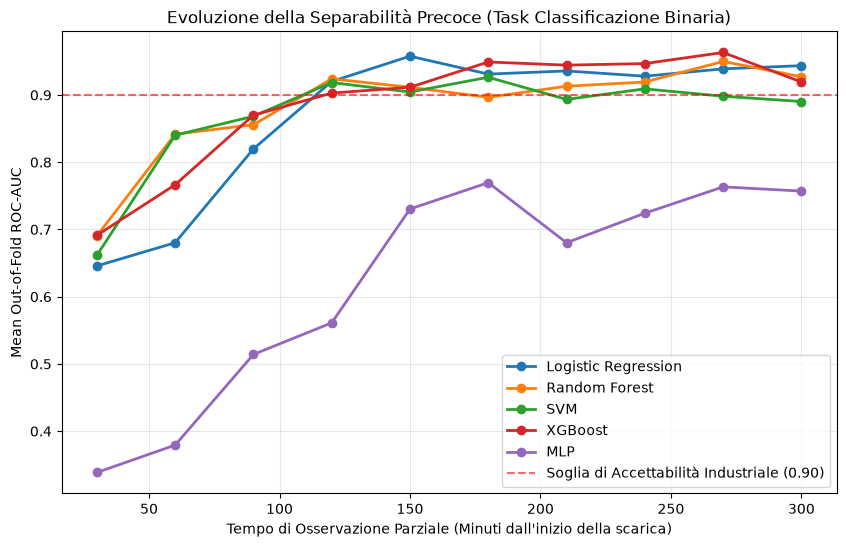

In [10]:
plot_roc_auc_over_time(storico_risultati, END_WINDOW_TEST)

# Window time choice

Based on the ROC-AUC results, the [90/120] window is chosen as a good compromise between early prediction and model reliability. The ROC-AUC curve shows that the predictive information accumulates over time, and the [90/120] window captures most of the relevant features while still allowing for a significant reduction in test duration compared to the full 14-hour discharge cycle, providing a practical solution for the battery testing lab.


# Hyperparameter Tuning

The previous chapter illustrated how to design, train and evaluate different models, but to increase the goodness of the models, hyperparameter tuning is needed. The hyperparameter tuning is done with a `GridSearchCV` on the [90/120] window, which was chosen as a good compromise between early prediction and model reliability. The `GridSearchCV` uses a 3-fold `StratifiedGroupKFold` CV inside a `StandardScaler + Classifier` pipeline for each model. The output is one out-of-fold ROC-AUC per (model, hyperparameter) pair, using the best hyperparameters for each model. The goal of this phase is to find the best hyperparameters for each model, which will be used in the final evaluation on the Test set.

In [ ]:

# Usiamo la finestra ottimale emersa dai tuoi test (es. 60 minuti)
START_WINDOW = 90
END_WINDOW = 120

exclude_cols = {'label', 'file_name', 'start_time', 'end_time'}

# 1. Costruzione della matrice di Train per il Tuning
train_records = []
for file_name in file_train_val:
    df_bat = battery_dict[file_name]
    label = summary_train_df[summary_train_df['file_name'] == file_name]['label'].values[0]
    feat = extract_features_from_battery(df_bat, window_minutes=END_WINDOW, starting_minute=START_WINDOW)
    if feat is not None and not np.isnan(feat['delta_voltage']):
        feat['file_name'] = file_name
        feat['label'] = label
        train_records.append(feat)
        
df_tuning = pd.DataFrame(train_records).bfill().ffill()
feature_names = [c for c in df_tuning.columns if c not in exclude_cols]

X_train = df_tuning[feature_names].values
y_train = df_tuning['label'].values
groups_train = df_tuning['file_name'].values

# 2. Definizione delle "Griglie" di parametri per ciascun modello
# NOTA: Usando la Pipeline, dobbiamo anteporre 'clf__' ai nomi dei parametri!
param_grids = {
    "Logistic Regression": {
        'clf__C': [0.01, 0.1, 1.0, 10.0],
        'clf__l1_ratio': [0.0, 1.0]
    },
    "Random Forest": {
        'clf__n_estimators': [50, 100, 200],
        'clf__max_depth': [4, 6, 8, 12],
        'clf__min_samples_split': [2, 5]
    },
    "SVM": {
        # Per la SVM calibrata, dobbiamo entrare dentro l'estimator specficiando 'clf__estimator__'
        'clf__estimator__C': [0.1, 1.0, 10.0],
        'clf__estimator__kernel': ['linear', 'rbf'],
        'clf__estimator__gamma': ['scale', 'auto']
    },
    "XGBoost": {
        'clf__n_estimators': [50, 100, 150],
        'clf__max_depth': [3, 4, 6],
        'clf__learning_rate': [0.01, 0.05, 0.1]
    },
    "MLP": {
        'clf__hidden_layer_sizes': [(32, 16), (64, 32), (64, 64)],
        'clf__alpha': [0.001, 0.01, 0.1]
    }
}

# Dizionario dove salveremo i modelli ottimizzati pronti per il test set finale
modelli_ottimizzati = {}

# 3. Ciclo di ottimizzazione
sgkf = StratifiedGroupKFold(n_splits=5)

for name, model_instance in modelli.items():   
    # Creiamo la pipeline standardizzata
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('clf', model_instance)
    ])
    
    # Configuriaramo il GridSearch con StratifiedGroupKFold e scoring basato su ROC-AUC
    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        cv=sgkf,
        scoring='roc_auc',
        n_jobs=-1,
        verbose=1
    )
    
    # Eseguiamo il fit passando esplicitamente i gruppi (i nomi dei file delle batterie)
    grid_search.fit(X_train, y_train, groups=groups_train)
    
    # Salviamo il modello migliore (già ri-addestrato su tutto X_train con i parametri ottimi)
    modelli_ottimizzati[name] = grid_search.best_estimator_

optimized_results = evaluate_models(
    models=modelli_ottimizzati,
    window_start=START_WINDOW_TEST,
    window_end=END_WINDOW_TEST,
    battery_dict=battery_dict,
    summary_train_df=summary_train_df,
    file_train_val=file_train_val
)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Fitting 5 folds for each of 24 candidates, totalling 120 fits
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Fitting 5 folds for each of 27 candidates, totalling 135 fits


c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\joblib\externals\loky\process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Fitting 5 folds for each of 9 candidates, totalling 45 fits


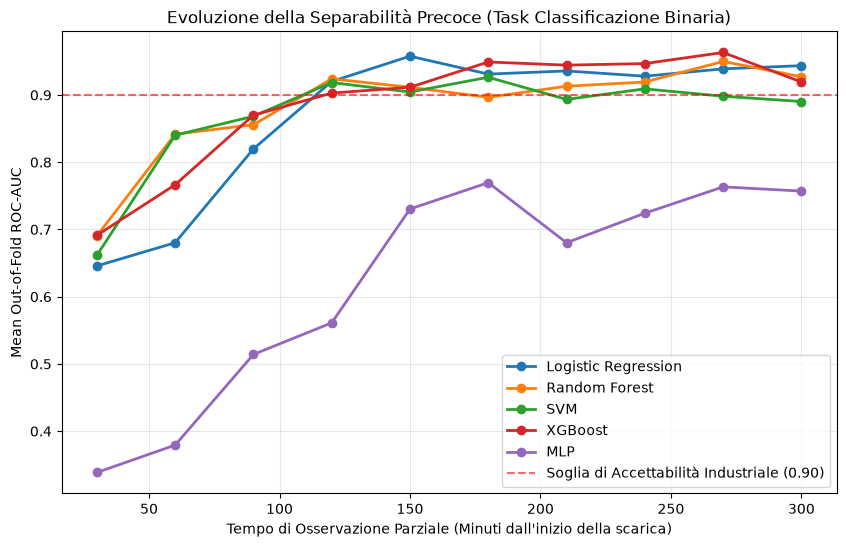

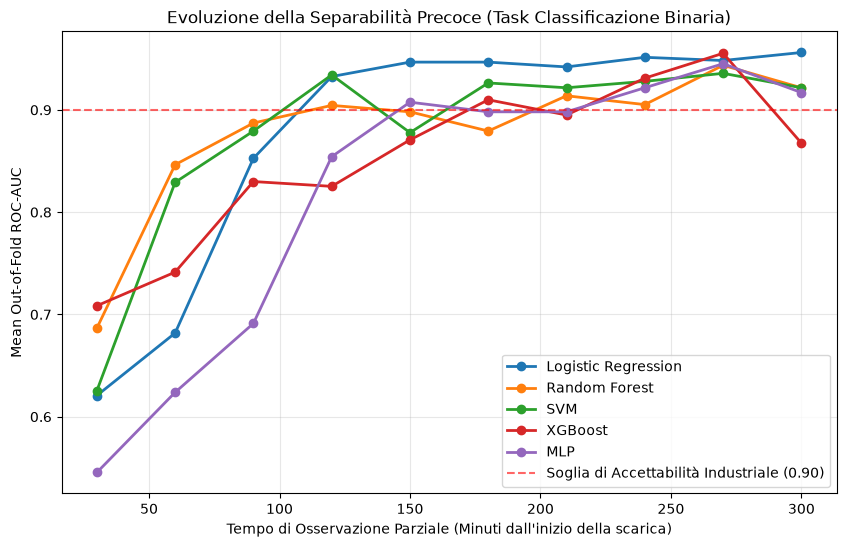

In [12]:
plot_roc_auc_over_time(storico_risultati, END_WINDOW_TEST)
plot_roc_auc_over_time(optimized_results, END_WINDOW_TEST)

### ROC-AUC over Time: Baseline vs. Tuned

The two plots compare out-of-fold AUC across the 10 observation windows before and after hyperparameter tuning.

What to read from the plots:
- **Slope**: how quickly information accumulates. A steep rise in the first 30–60 minutes means early windows are already discriminative.
- **Saturation point**: the window after which AUC flattens. This is the practical early-exit candidate.
- **Tuning gain**: the gap between baseline and optimized curves. Models with many sensitive hyperparameters — SVM ($C$, $\gamma$) and LR ($C$, `l1_ratio`) — tend to show the largest gains.
- **0.90 reference line**: a threshold commonly used as a benchmark for operational deployment.


              precision    recall  f1-score   support

        FAIL       1.00      0.62      0.77         8
     SUCCESS       0.62      1.00      0.77         5

    accuracy                           0.77        13
   macro avg       0.81      0.81      0.77        13
weighted avg       0.86      0.77      0.77        13



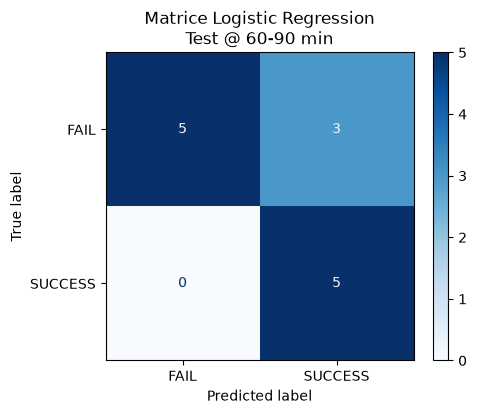

              precision    recall  f1-score   support

        FAIL       1.00      0.75      0.86         8
     SUCCESS       0.71      1.00      0.83         5

    accuracy                           0.85        13
   macro avg       0.86      0.88      0.85        13
weighted avg       0.89      0.85      0.85        13



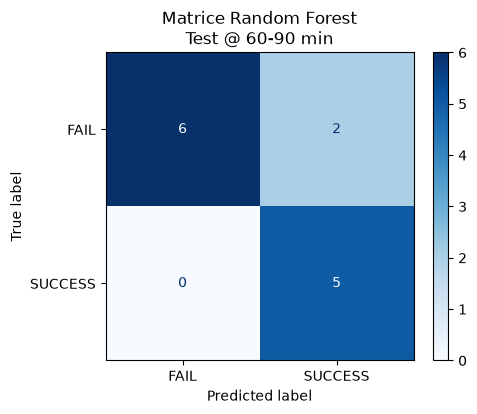

              precision    recall  f1-score   support

        FAIL       1.00      0.62      0.77         8
     SUCCESS       0.62      1.00      0.77         5

    accuracy                           0.77        13
   macro avg       0.81      0.81      0.77        13
weighted avg       0.86      0.77      0.77        13



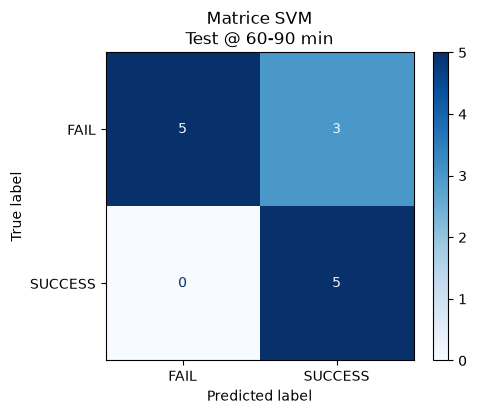

              precision    recall  f1-score   support

        FAIL       1.00      0.50      0.67         8
     SUCCESS       0.56      1.00      0.71         5

    accuracy                           0.69        13
   macro avg       0.78      0.75      0.69        13
weighted avg       0.83      0.69      0.68        13



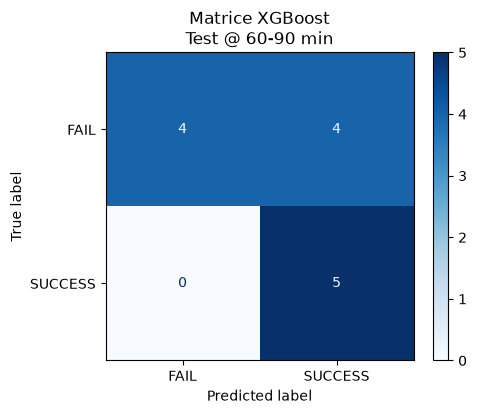

              precision    recall  f1-score   support

        FAIL       0.73      1.00      0.84         8
     SUCCESS       1.00      0.40      0.57         5

    accuracy                           0.77        13
   macro avg       0.86      0.70      0.71        13
weighted avg       0.83      0.77      0.74        13



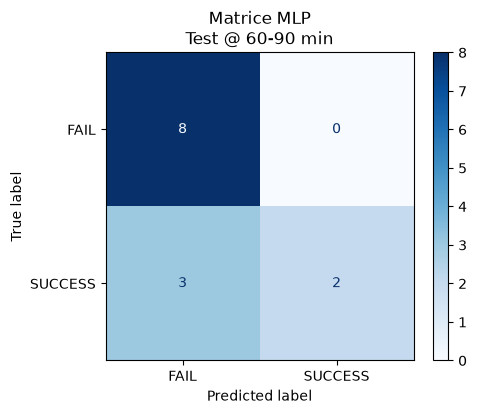

In [13]:
exclude_cols = {'label', 'file_name', 'start_time', 'end_time'}

# 1. Preparazione dell'intero Training Set alla finestra stabilita
train_records = []
for file_name in file_train_val:
    df_bat = battery_dict[file_name]
    label = summary_train_df[summary_train_df['file_name'] == file_name]['label'].values[0]
    
    # Invocazione del tuo metodo nativo
    feat = extract_features_from_battery(df_bat, window_minutes=END_WINDOW, starting_minute=START_WINDOW)
    if feat is not None and not np.isnan(feat['delta_voltage']):
        feat['label'] = label
        train_records.append(feat)
        
df_train_final = pd.DataFrame(train_records).bfill().ffill()
feature_names = [c for c in df_train_final.columns if c not in exclude_cols]

X_train_f = df_train_final[feature_names].values
y_train_f = df_train_final['label'].values


# 2. Preparazione dell'Test Test Set (Dati mai visti, sigillati all'inizio)
test_records = []
for file_name in file_Test_test:
    df_bat = battery_dict[file_name]
    label = summary_test_df[summary_test_df['file_name'] == file_name]['label'].values[0]
    
    feat = extract_features_from_battery(df_bat, window_minutes=END_WINDOW, starting_minute=START_WINDOW)
    if feat is not None and not np.isnan(feat['delta_voltage']):
        feat['label'] = label
        test_records.append(feat)
        
df_test_final = pd.DataFrame(test_records).bfill().ffill()

X_test_f = df_test_final[feature_names].values
y_test_f = df_test_final['label'].values


# 3. Ciclo dinamico di Fit e Test su ogni modello configurato
for name, model_instance in modelli_ottimizzati.items():
    
    # Creiamo una pipeline fresca per il modello corrente per garantire lo scaling isolato
    pipeline_definitiva = Pipeline([
        ('scaler', StandardScaler()), 
        ('clf', model_instance)
    ])
    
    # --- FIT GLOBAL SUL TRAIN SET ---
    pipeline_definitiva.fit(X_train_f, y_train_f)
    
    # --- PREDDIZIONE SULL'Test SET ---
    y_pred_f = pipeline_definitiva.predict(X_test_f)
    
    # Stampa dei risultati testuali (Precision, Recall, F1-Score)
    print(classification_report(y_test_f, y_pred_f, target_names=['FAIL', 'SUCCESS']))
    
    # Generazione e visualizzazione della Matrice di Confusione
    cm = confusion_matrix(y_test_f, y_pred_f)
    fig, ax = plt.subplots(figsize=(5, 4))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['FAIL', 'SUCCESS'])
    disp.plot(cmap=plt.cm.Blues, ax=ax, values_format='d')
    plt.title(f"Matrice {name}\nTest @ {START_WINDOW}-{END_WINDOW} min")
    plt.show()

### Final Classification Results on Test Set

Each model is retrained on the full training set with the best hyperparameters from `GridSearchCV`, then evaluated once on the Test set — cells that were never seen during training or tuning.

The confusion matrix layout:

| Prediction \ Truth | FAIL (0) | PASS (1) |
|---|---|---|
| **FAIL (0)** | TN | FN |
| **PASS (1)** | **FP** | TP |

**FP is the costliest error here**: a degraded cell predicted as PASS means certifying a cell that should go to reconditioning. In this domain, we prioritize minimizing FP, so Precision is the most operationally relevant metric alongside AUC.

### Learning Curves


In [14]:
def plot_learning_curve(
        models_to_analyze,
        X_train,
        y_train,
        groups_train):
    
    for model_name, model_to_analyze in models_to_analyze.items():
        sgkf = StratifiedGroupKFold(n_splits=3)
        train_sizes, train_scores, test_scores = learning_curve(
            estimator=model_to_analyze,
            X=X_train,
            y=y_train,
            groups=groups_train,
            train_sizes=np.linspace(0.2, 1.0, 5),
            cv=sgkf,
            scoring='roc_auc',
            n_jobs=-1,
            random_state=RANDOM_SEED
        )
        train_mean = np.mean(train_scores, axis=1)
        train_std = np.std(train_scores, axis=1)
        test_mean = np.mean(test_scores, axis=1)
        test_std = np.std(test_scores, axis=1)

        plt.figure(figsize=(10, 6))
        plt.plot(train_sizes, train_mean, color='blue', marker='o', markersize=5, label='Training ROC-AUC')
        plt.fill_between(train_sizes, train_mean + train_std, train_mean - train_std, alpha=0.15, color='blue')

        plt.plot(train_sizes, test_mean, color='green', linestyle='--', marker='s', markersize=5, label='Validation ROC-AUC (CV)')
        plt.fill_between(train_sizes, test_mean + test_std, test_mean - test_std, alpha=0.15, color='green')

        plt.title("Learning Curves - Modello: {}".format(model_name))
        plt.xlabel("Numero di campioni (Batterie) usati nel Training")
        plt.ylabel("Punteggio ROC-AUC")
        plt.grid(True, alpha=0.3)
        plt.legend(loc='lower right')
        plt.show()

c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\sklearn\model_selection\_validation.py:489: FitFailedWarning: 
2 fits failed out of a total of 15.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
2 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\sklearn\model_selection\_validation.py", line 856, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\sklear

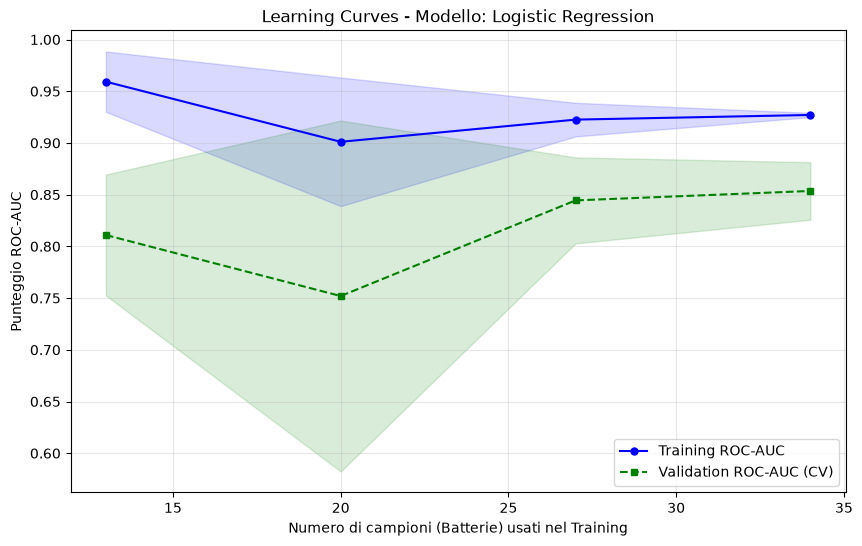

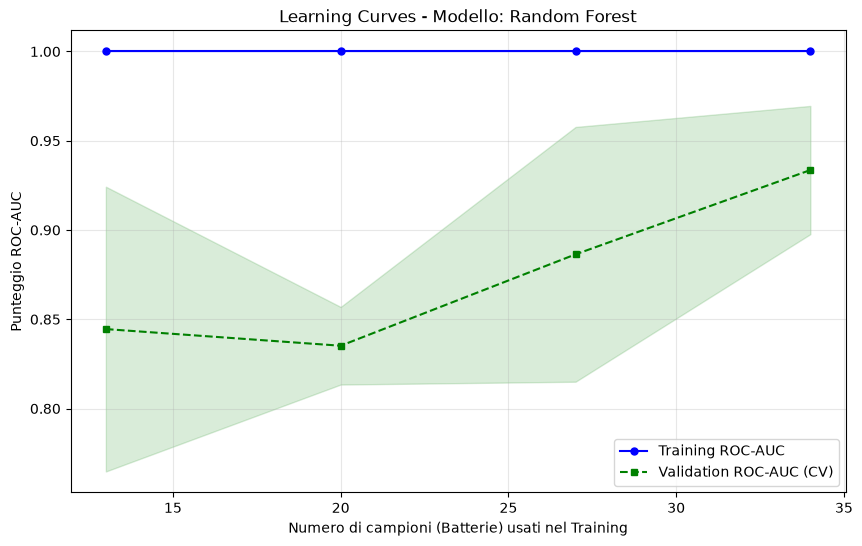

c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\sklearn\model_selection\_validation.py:489: FitFailedWarning: 
4 fits failed out of a total of 15.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
2 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\sklearn\model_selection\_validation.py", line 856, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\sklear

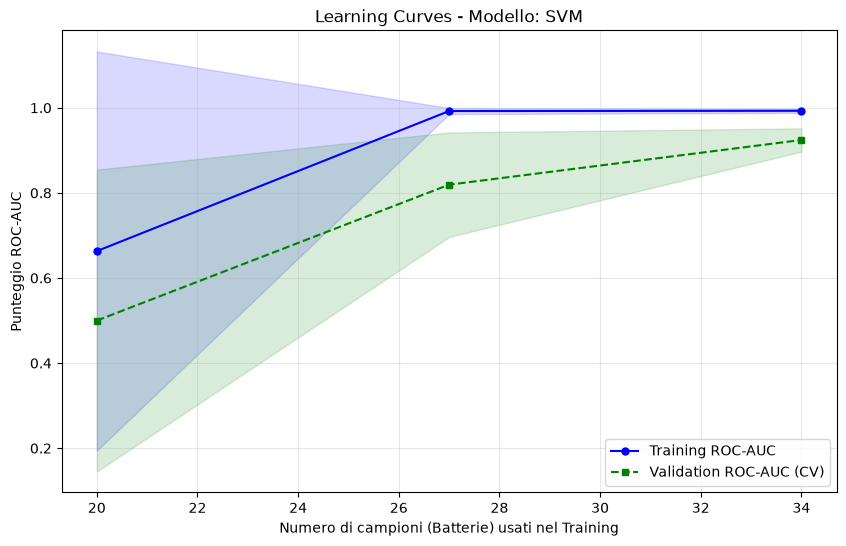

c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\sklearn\model_selection\_validation.py:489: FitFailedWarning: 
2 fits failed out of a total of 15.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
2 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\sklearn\model_selection\_validation.py", line 856, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\sklear

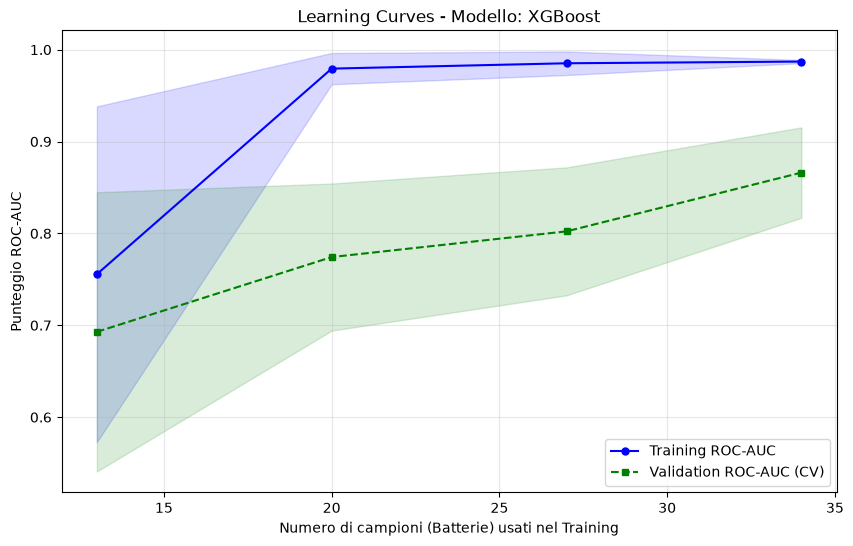

c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\sklearn\model_selection\_validation.py:489: FitFailedWarning: 
3 fits failed out of a total of 15.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
2 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\sklearn\model_selection\_validation.py", line 856, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\sklear

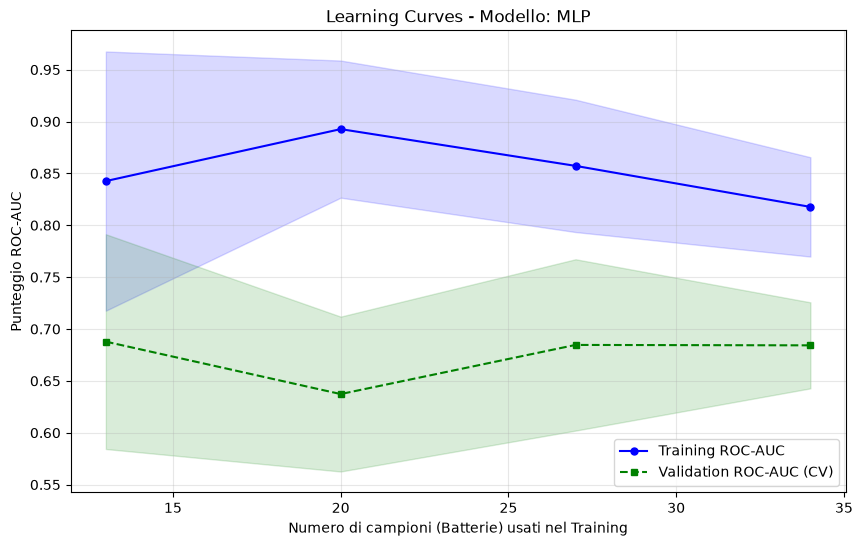

In [15]:
plot_learning_curve(
    models_to_analyze=modelli_ottimizzati,
    X_train=X_train_f,
    y_train=y_train_f,
    groups_train=groups_train
)

### Learning Curves — Overfitting Check

The learning curves show ROC-AUC (train vs. CV validation) as a function of training set size, using `StratifiedGroupKFold(3)`.

- **Large train-val gap**: the model overfits. With ~60–80 total files (80% for training), this is a real risk for high-capacity models like XGBoost and MLP.
- **Both curves flat and low**: underfitting — the model lacks capacity to capture discharge dynamics from these 12 features.
- **Shaded bands**: ±1 std across folds. Wide bands indicate high sensitivity to which files end up in each fold — a consequence of the small dataset.

The overfitting observed here for some models motivates the regularization strategies used in both the classical ML pipeline (L2, balanced class weights) and the deep learning section (Dropout, weight decay, augmentation).


# Task 2 - Early Regression (Continuous Capacity Estimation)


## Regression with Machine Learning Models

Instead of a binary label, here we predict $C_{\mathrm{final}}$ directly as a continuous value. The advantage over Task 1 is that we use all the information in the capacity distribution — not just which side of the 5.0 Ah threshold a cell falls on. By thresholding the regression output at 5.0 Ah we can still get a binary decision, allowing direct comparison with Task 1 results.

### Feature Design: Lagged Blocks

For regression we use a different extraction strategy. We split the history before a cut-off $t_{\text{end}}$ into $L = 4$ backward-looking blocks of width $\Delta t = 20$ min:

$$\text{Block}_k = [t_{\text{end}} - (k+1) \cdot 20,\;\; t_{\text{end}} - k \cdot 20], \quad k = 0, 1, 2, 3$$

Each block contributes 7 features: $\dot{V}$, $\bar{V}$, $\sigma_V$, $\dot{C}$, $V_{\text{start}}$, $V_{\text{end}}$, $C_{\text{end}}$. Total: $4 \times 7 = 28$ features, labelled with suffixes `_t`, `_t-1`, `_t-2`, `_t-3`.

The rationale: the trajectory of these 7 descriptors over the 4 most recent 20-minute blocks encodes temporal dynamics — how the voltage slope and capacity rate are evolving — which a single-window aggregate would miss.

### Observation Window Search

We test four cut-offs: $t_{\text{end}} \in \{60, 90, 120, 150\}$ min. For each, we run `GridSearchCV` with `GroupKFold(5)` and record train and validation RMSE. Per model, we pick the **shortest** window whose validation RMSE is within 0.025 Ah of the absolute best — a tolerance that trades a negligible accuracy loss for an earlier prediction.


In [16]:
# aggregation by step of 10 minutes

# Configurazione della finestra critica e dei blocchi storici a ritroso
MINUTO_FINE_OSSERVAZIONE = 500
AMPIEZZA_BLOCCO_MINUTI = 20
NUMERO_LAG = 4  # Genera i blocchi temporali: t (80-90), t-1 (70-80), t-2 (60-70), t-3 (60-70)

# Sostituisci con il nome reale della colonna della capacità finale nel tuo summary_df
COLONNA_TARGET_Y = 'final_capacity' 

def extract_regression_lagged_features(df, base_window_min=10, steps=3, end_minute=90):
    """
    Estrae le feature fisiche aggregando i dati in blocchi temporali a ritroso.
    Restituisce un unico dizionario piatto con le feature laggate (_t, _t-1, _t-2, _t-3).
    """
    all_features = {}
    
    for step in range(steps):
        # Calcolo dei confini temporali del blocco corrente
        w_start = end_minute - (step + 1) * base_window_min
        w_end = end_minute - step * base_window_min
        
        if w_start < 0:
            break
            
        # Subset temporal filtering of the single battery test CSV
        truncated_df = df[(df['elapsed_min'] >= w_start) & (df['elapsed_min'] <= w_end)]
        
        # Controllo di sicurezza se mancano record nel blocco
        if len(truncated_df) < 2:
            return None 
            
        # Calculus of physical slopes and averages over the block
        delta_voltage = truncated_df['Tensione (V)'].iloc[-1] - truncated_df['Tensione (V)'].iloc[0]
        dv_dt = delta_voltage / base_window_min
        v_mean = truncated_df['Tensione (V)'].mean()
        v_std = truncated_df['Tensione (V)'].std()
        
        delta_C = truncated_df['Capacity (Ah)'].iloc[0] - truncated_df['Capacity (Ah)'].iloc[-1]
        dC_dt = delta_C / base_window_min
        
        v_start = truncated_df['Tensione (V)'].iloc[0]
        v_end = truncated_df['Tensione (V)'].iloc[-1]
        c_end = truncated_df['Capacity (Ah)'].iloc[-1]
        
        # Indentification suffix for lagged features
        suffix = f"_t" if step == 0 else f"_t-{step}"
        
        # Feature mapping with suffixes for lagged features
        all_features[f'dv_dt{suffix}'] = dv_dt
        all_features[f'mean_voltage{suffix}'] = v_mean
        all_features[f'std_voltage{suffix}'] = v_std
        all_features[f'dC_dt{suffix}'] = dC_dt
        all_features[f'voltage_start{suffix}'] = v_start
        all_features[f'voltage_end{suffix}'] = v_end
        all_features[f'capacity_end{suffix}'] = c_end

    return all_features

# Train / Validation Set (20% Test test set)
train_regression_records = []
for file_name in file_train_val:
    df_bat = battery_dict[file_name]
    # Recover the value of the continuous target (final capacity) from the summary DataFrame
    y_val = summary_train_df[summary_train_df['file_name'] == file_name][COLONNA_TARGET_Y].values[0]
    
    feat_reg = extract_regression_lagged_features(
        df_bat, base_window_min=AMPIEZZA_BLOCCO_MINUTI, steps=NUMERO_LAG, end_minute=MINUTO_FINE_OSSERVAZIONE
    )
    
    if feat_reg is not None:
        feat_reg['file_name'] = file_name
        feat_reg['target_capacity'] = y_val  # Nuovo target Continuo (Y)
        train_regression_records.append(feat_reg)

df_reg_train = pd.DataFrame(train_regression_records).bfill().ffill()

# extract the same features for the Test test set
test_regression_records = []
for file_name in file_Test_test:
    df_bat = battery_dict[file_name]
    y_val = summary_test_df[summary_test_df['file_name'] == file_name][COLONNA_TARGET_Y].values[0]
    
    feat_reg = extract_regression_lagged_features(
        df_bat, base_window_min=AMPIEZZA_BLOCCO_MINUTI, steps=NUMERO_LAG, end_minute=MINUTO_FINE_OSSERVAZIONE
    )
    
    if feat_reg is not None:
        feat_reg['file_name'] = file_name
        feat_reg['target_capacity'] = y_val
        test_regression_records.append(feat_reg)

df_reg_test = pd.DataFrame(test_regression_records).bfill().ffill()

# Matrix isolation for regression tasks
exclude_reg_cols = {'target_capacity', 'file_name', 'start_time', 'end_time', 'label'}
feature_reg_names = [c for c in df_reg_train.columns if c not in exclude_reg_cols]

X_train_r = df_reg_train[feature_reg_names].values
y_train_r = df_reg_train['target_capacity'].values
groups_train_r = df_reg_train['file_name'].values

X_test_r = df_reg_test[feature_reg_names].values
y_test_r = df_reg_test['target_capacity'].values

In [17]:
modelli_regressione = {
    "Random Forest Regressor": RandomForestRegressor(random_state=RANDOM_SEED, n_jobs=-1),
    "XGBoost Regressor": XGBRegressor(random_state=RANDOM_SEED, n_jobs=-1, eval_metric='rmse'),
    "Support Vector Regressor (SVR)": SVR()
}

# specific hyperparameter grids for regression tasks
param_grids_regression = {
    "Random Forest Regressor": {
        'clf__n_estimators': [50, 100, 200],
        'clf__max_depth': [4, 6, 8],
        'clf__min_samples_leaf': [1, 3, 5]
    },
    "XGBoost Regressor": {
        'clf__n_estimators': [50, 100, 150],
        'clf__max_depth': [3, 4, 5],
        'clf__learning_rate': [0.01, 0.05, 0.1]
    },
    "Support Vector Regressor (SVR)": {
        'clf__C': [0.1, 1.0, 10.0, 50.0],
        'clf__kernel': ['linear', 'rbf'],
        'clf__gamma': ['scale', 'auto']
    }
}

### Regression Models

Three models covering a range of inductive biases:

- **Random Forest Regressor**: bootstrap aggregation of depth-limited trees. Captures non-linear interactions without hand-tuning; shallow individual trees limit overfitting on small datasets.

- **XGBoost Regressor**: gradient-boosted trees with $\ell_1$/$\ell_2$ leaf regularization and shrinkage (`learning_rate`). Generally the strongest off-the-shelf model for structured tabular data.

- **SVR** (Support Vector Regressor): finds the flattest function within an $\varepsilon$-insensitive tube using an RBF kernel. Good generalization on small datasets when the target is smooth in the kernel space. Scale-sensitive — must use `StandardScaler`.

All three are wrapped in a `StandardScaler → Regressor` pipeline.


In [18]:
# Liste per salvare i punteggi da plottare
nomi_modelli = []
rmse_train_list = []
rmse_val_list = []

# NOTA OTTIMIZZATA: Per integrarlo direttamente nel tuo flusso attuale, ecco la funzione di tuning 
# modificata che sputa fuori il grafico di Overfitting/Underfitting automaticamente:

def tune_and_diagnose_regression(cut_off_minute, battery_dict, summary_train_df, file_train_val):
    records_tuning = []
    for file_name in file_train_val:
        df_bat = battery_dict[file_name]
        y_val = summary_train_df[summary_train_df['file_name'] == file_name]['final_capacity'].values[0]
        feat_reg = extract_regression_lagged_features(df_bat, base_window_min=AMPIEZZA_BLOCCO_MINUTI, steps=NUMERO_LAG, end_minute=cut_off_minute)
        if feat_reg is not None:
            feat_reg['file_name'] = file_name
            feat_reg['target_capacity'] = y_val
            records_tuning.append(feat_reg)
            
    df_tuning_r = pd.DataFrame(records_tuning).bfill().ffill()
    exclude_cols = {'target_capacity', 'file_name', 'start_time', 'end_time', 'label'}
    feature_names = [c for c in df_tuning_r.columns if c not in exclude_cols]
    
    X_train = df_tuning_r[feature_names].values
    y_train = df_tuning_r['target_capacity'].values
    groups_train = df_tuning_r['file_name'].values
    
    gkf = GroupKFold(n_splits=5)
    
    #fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    modelli_reg_ottimizzati = {}
    rmse_train_list = {}
    rmse_val_list = {}
    
    for idx, (name, model_instance) in enumerate(modelli_regressione.items()):
        pipeline = Pipeline([('scaler', StandardScaler()), ('clf', model_instance)])
        
        # AGGIORNAMENTO CRUCIALE: Forziamo il calcolo del punteggio anche sul Training di ogni fold
        grid_search = GridSearchCV(
            estimator=pipeline,
            param_grid=param_grids_regression[name],
            cv=gkf,
            scoring='neg_mean_squared_error',
            return_train_score=True, # <--- CALCOLA IL TRAIN SCORE DI FOLD
            n_jobs=-1
        )
        grid_search.fit(X_train, y_train, groups=groups_train)
        
        # Estraiamo i punteggi della combinazione migliore di iperparametri
        best_index = grid_search.best_index_
        mean_train_neg_mse = grid_search.cv_results_['mean_train_score'][best_index]
        mean_val_neg_mse = grid_search.cv_results_['mean_test_score'][best_index]
        
        # Convertiamo in RMSE positivo (Ah)
        rmse_train = np.sqrt(-mean_train_neg_mse)
        rmse_val = np.sqrt(-mean_val_neg_mse)
        
        #print(f"\n[+] {name}:")
        #print(f"    -> Errore medio sul TRAIN:      {rmse_train:.4f} Ah")
        #print(f"    -> Errore medio in VALIDATION: {rmse_val:.4f} Ah")
        
    
        modelli_reg_ottimizzati[name] = grid_search.best_estimator_
        rmse_train_list[name] = rmse_train
        rmse_val_list[name] = rmse_val

    
    return modelli_reg_ottimizzati, feature_names, rmse_train_list, rmse_val_list

### Diagnostic Tuning: Train vs. Validation RMSE

`tune_and_diagnose_regression` runs `GridSearchCV` with `return_train_score=True`, so we get both train and validation RMSE at the best hyperparameter configuration for each model.

The gap $\Delta = \text{RMSE}_{\text{val}} - \text{RMSE}_{\text{train}}$ tells us the learning regime:

| Gap | Regime |
|---|---|
| $\approx 0$, both low | Good generalization |
| $\gg 0$, train low | Overfitting |
| $\approx 0$, both high | Underfitting |

We run this for all four cut-off windows $\{60, 90, 120, 150\}$ min. The resulting plots show train/val RMSE vs. observation time — both the accuracy vs. time trade-off and the overfitting tendency are visible in a single chart.



=== Analisi per finestra di osservazione: 60 minuti ===

=== Analisi per finestra di osservazione: 90 minuti ===

=== Analisi per finestra di osservazione: 120 minuti ===

=== Analisi per finestra di osservazione: 150 minuti ===


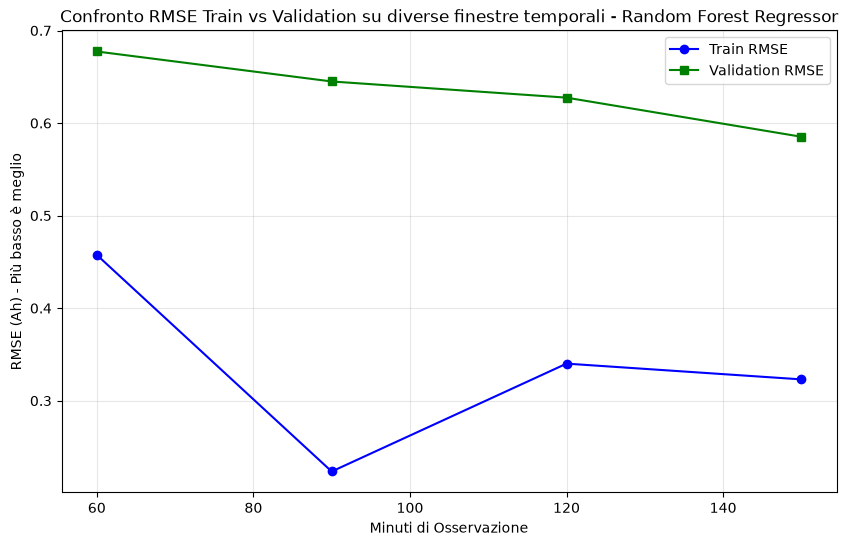

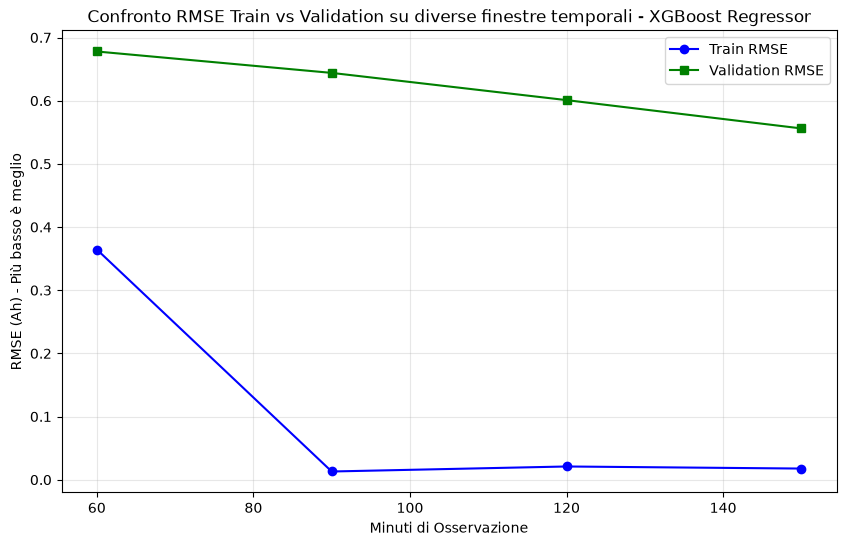

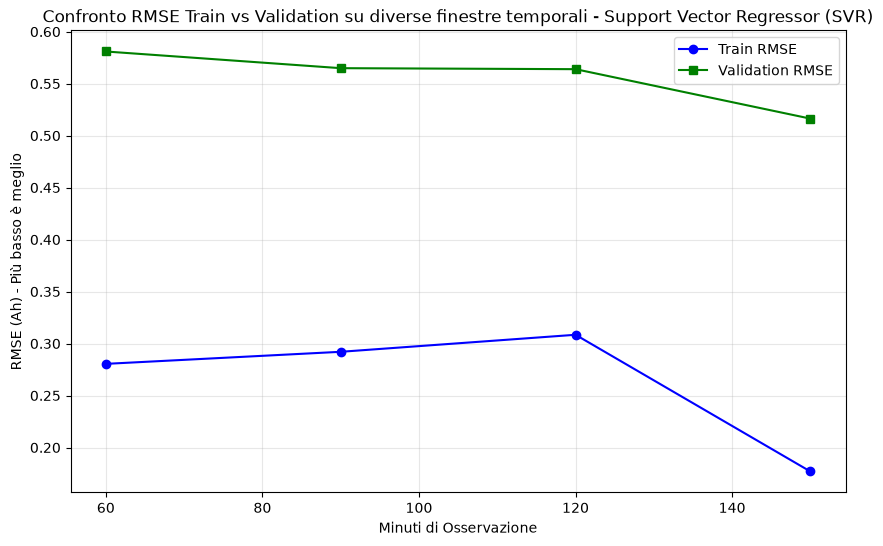

=== Random Forest Regressor ===
 -> Minimo teorico assoluto: 0.585 Ah
 -> Finestra ottima scelta (con compromesso): 150 minuti (RMSE: 0.585 Ah)

=== XGBoost Regressor ===
 -> Minimo teorico assoluto: 0.556 Ah
 -> Finestra ottima scelta (con compromesso): 150 minuti (RMSE: 0.556 Ah)

=== Support Vector Regressor (SVR) ===
 -> Minimo teorico assoluto: 0.516 Ah
 -> Finestra ottima scelta (con compromesso): 150 minuti (RMSE: 0.516 Ah)

Selected index for best model Random Forest Regressor: 3
Selected index for best model XGBoost Regressor: 3
Selected index for best model Support Vector Regressor (SVR): 3


In [19]:
ARR_MINUTI_OSSERVAZIONE = [60,90,120,150]

rmse_train_list = []
rmse_val_list = []
modelli_reg_ottimi_list = []
feature_reg_selezionate_list = []
for timespan in ARR_MINUTI_OSSERVAZIONE:
    print(f"\n=== Analisi per finestra di osservazione: {timespan} minuti ===")
    modelli_reg_ottimi_tmp, feature_reg_selezionate_tmp, rmse_train_list_tmp, rmse_val_list_tmp = tune_and_diagnose_regression(
        cut_off_minute=timespan,
        battery_dict=battery_dict,
        summary_train_df=summary_train_df,
        file_train_val=file_train_val
    )
    rmse_train_list.append(rmse_train_list_tmp)
    rmse_val_list.append(rmse_val_list_tmp)
    modelli_reg_ottimi_list.append(modelli_reg_ottimi_tmp)
    feature_reg_selezionate_list.append(feature_reg_selezionate_tmp)

# Compare the RMSE values across different observation windows
# this should be done for each model
for model_name in modelli_regressione.keys():
    train_rmse = [rmse_train[model_name] for rmse_train in rmse_train_list]
    val_rmse = [rmse_val[model_name] for rmse_val in rmse_val_list]
    plt.figure(figsize=(10, 6))
    plt.plot(ARR_MINUTI_OSSERVAZIONE, train_rmse, marker='o', label='Train RMSE', color='blue')
    plt.plot(ARR_MINUTI_OSSERVAZIONE, val_rmse, marker='s', label='Validation RMSE', color='green')
    plt.title(f"Confronto RMSE Train vs Validation su diverse finestre temporali - {model_name}")
    plt.xlabel("Minuti di Osservazione")
    plt.ylabel("RMSE (Ah) - Più basso è meglio")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

# Choose one of the observation windows based on the RMSE comparison for final testing
# The window should be the one with the lowest validation RMSE and acceptable train RMSE (to avoid overfitting)
#best_index = {}
final_regression_model = {}
final_feature_names = {}
'''for model_name in modelli_regressione.keys():
    best_index[model_name] = np.argmin([rmse_val[model_name] for rmse_val in rmse_val_list])
    best_observation_window = ARR_MINUTI_OSSERVAZIONE[best_index[model_name]]
    print(f"Best observation window for {model_name}: {best_observation_window} minutes")'''

# Impostiamo una tolleranza: quanti Ah siamo disposti a sacrificare per avere la predizione prima?
TOLLERANZA_AH = 0.025 

best_index = {}
for model_name in modelli_regressione.keys():
    # Estrarre la lista degli RMSE di validazione per il modello corrente
    val_rmse_vettore = [rmse_val[model_name] for rmse_val in rmse_val_list]
    
    # Trova il minimo assoluto (la tua vecchia euristica)
    min_rmse_assoluto = np.min(val_rmse_vettore)
    
    # Trova tutti gli indici in cui l'errore è vicino al minimo entro la tolleranza
    indici_accettabili = np.where(val_rmse_vettore <= (min_rmse_assoluto + TOLLERANZA_AH))[0]
    
    # Tra gli indici accettabili, prendiamo il PRIMO (ovvero la finestra temporale più BREVE/PRECOCE)
    best_index[model_name] = indici_accettabili[0]
    
    best_observation_window = ARR_MINUTI_OSSERVAZIONE[best_index[model_name]]
    rmse_scelto = val_rmse_vettore[best_index[model_name]]
    
    print(f"=== {model_name} ===")
    print(f" -> Minimo teorico assoluto: {min_rmse_assoluto:.3f} Ah")
    print(f" -> Finestra ottima scelta (con compromesso): {best_observation_window} minuti (RMSE: {rmse_scelto:.3f} Ah)\n")

for model_name, index in best_index.items():
    print(f"Selected index for best model {model_name}: {index}")
    final_regression_model[model_name] = modelli_reg_ottimi_list[index][model_name]
    final_feature_names[model_name] = feature_reg_selezionate_list[index]

### Window Selection Results

The plots show train and validation RMSE for each model across the four cut-off windows. Per model, the chosen window is the earliest one with validation RMSE $\leq \min(\text{val RMSE}) + 0.025$ Ah. This 25 mAh tolerance is negligible compared to the typical RMSE values, but it can save 30–60 minutes of test time per cell.

`final_regression_model` stores the ready-to-predict pipeline for each model at its selected cut-off window.


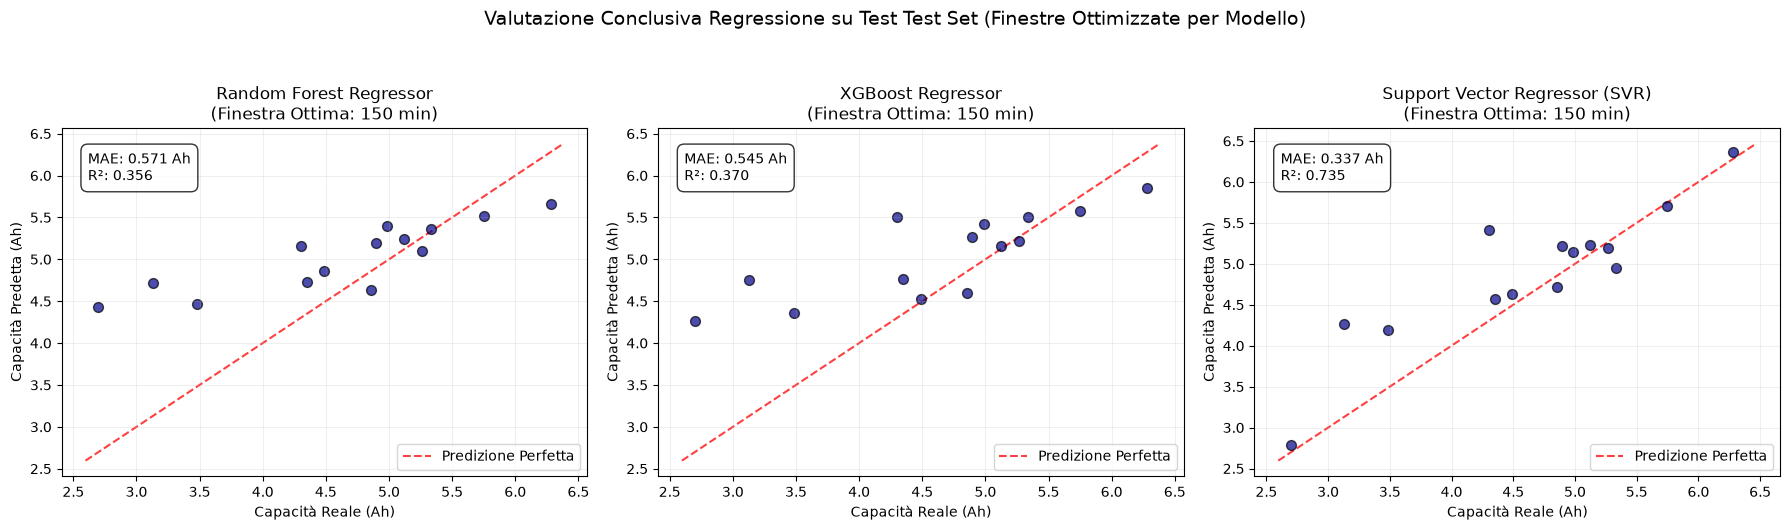

In [20]:
# 2. Predizione e Plotting True vs Predicted (Inizializziamo la figura prima del ciclo)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Cicliamo in modo robusto su ciascun modello autonomamente
for idx, (name, pipeline_ottima) in enumerate(final_regression_model.items()):
    
    # CORREZIONE 1: Recuperiamo la finestra specifica ottimale per QUESTO modello
    model_best_window = ARR_MINUTI_OSSERVAZIONE[best_index[name]]
    # CORREZIONE 2: Recuperiamo la lista esatta delle feature estratte per QUELLA finestra
    model_feature_names = final_feature_names[name]
    
    # 1. Costruzione della matrice di TEST (Test) mirata sulla specifica finestra del modello
    test_regression_records = []
    for file_name in file_Test_test:
        df_bat = battery_dict[file_name]
        y_val = summary_test_df[summary_test_df['file_name'] == file_name]['final_capacity'].values[0]
        
        # Estraiamo le feature storiche usando il cut-off ottimale del modello corrente
        # Usiamo le variabili globali AMPIEZZA_BLOCCO_MINUTI e NUMERO_LAG se definite, altrimenti valori nativi (10 e 3)
        base_w = AMPIEZZA_BLOCCO_MINUTI if 'AMPIEZZA_BLOCCO_MINUTI' in globals() else 10
        n_steps = NUMERO_LAG if 'NUMERO_LAG' in globals() else 3
        
        feat_reg = extract_regression_lagged_features(
            df_bat, base_window_min=base_w, steps=n_steps, end_minute=model_best_window
        )
        
        if feat_reg is not None:
            feat_reg['file_name'] = file_name
            feat_reg['target_capacity'] = y_val
            test_regression_records.append(feat_reg)
            
    # Se per motivi di lunghezza dei CSV l'Test fallisse l'estrazione su finestre lunghe (es. 300 min)
    if not test_regression_records:
        print(f"⚠️ Attenzione: Impossibile estrarre dati di test per {name} alla finestra {model_best_window} min.")
        continue
        
    df_reg_test = pd.DataFrame(test_regression_records).bfill().ffill()
    
    # CORREZIONE 3: Estraiamo la matrice usando le feature specifiche salvate nel dizionario
    X_test_r = df_reg_test[model_feature_names].values
    y_test_r = df_reg_test['target_capacity'].values
    
    # Il modello è già addestrato e configurato, facciamo il predict
    y_pred_r = pipeline_ottima.predict(X_test_r)
    
    # Calcolo delle metriche di test reali
    mae = mean_absolute_error(y_test_r, y_pred_r)
    r2 = r2_score(y_test_r, y_pred_r)
    
    # Grafica sul sotto-plot del modello corrente
    ax = axes[idx]
    ax.scatter(y_test_r, y_pred_r, color='darkblue', alpha=0.7, edgecolors='k', s=50)
    
    # Linea di riferimento a 45 gradi
    lims = [min(y_test_r.min(), y_pred_r.min()) - 0.1, max(y_test_r.max(), y_pred_r.max()) + 0.1]
    ax.plot(lims, lims, 'r--', alpha=0.75, zorder=0, label="Predizione Perfetta")
    
    # Titolo dinamico che specifica anche quanti minuti sono serviti a quel modello
    ax.set_title(f"{name}\n(Finestra Ottima: {model_best_window} min)")
    ax.set_xlabel("Capacità Reale (Ah)")
    ax.set_ylabel("Capacità Predetta (Ah)")
    ax.grid(True, alpha=0.2)
    ax.text(0.05, 0.85, f"MAE: {mae:.3f} Ah\nR²: {r2:.3f}", 
            transform=ax.transAxes, bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))
    ax.legend(loc='lower right')

plt.suptitle("Valutazione Conclusiva Regressione su Test Test Set (Finestre Ottimizzate per Modello)", fontsize=14, y=1.05)
plt.tight_layout()
plt.show()

### Regression Results on Test Set

Each scatter plot shows true vs. predicted capacity on the Test set for one model at its optimal cut-off window. Points on the 45° diagonal are perfect predictions.

- **MAE (Ah)**: directly interpretable — for a cell near the 5.0 Ah decision threshold, a MAE of 0.3 Ah means the model can misclassify borderline cells.
- **$R^2$**: fraction of capacity variance explained by the early observation window. $R^2 > 0.8$ means the first 60–150 minutes are highly predictive of the final state.

Systematic bias (all points consistently above or below the diagonal) would indicate that the model under- or overestimates for a specific capacity range, which is worth checking for the heaviest-degraded or near-nominal cells.


# Deep Learning Models

In [21]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input, Conv1D, GlobalAveragePooling1D, LeakyReLU, MaxPooling1D, Flatten
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.model_selection import StratifiedShuffleSplit


### Deep Learning Approach

The classical ML pipelines compute 12–28 scalar features per window. That compresses the signal into a handful of statistics and throws away the temporal shape of the curve.

Here we feed the full 150-minute sequence — 151 time steps, 4 channels — directly into two architectures:

1. **LSTM**: reads the sequence step by step via gated recurrence. The forget/input/output gates can in principle capture cumulative discharge history. In practice, LSTMs need more training samples than CNNs to generalize, which is a known limitation at this dataset size.
2. **1D-CNN**: two convolutional blocks scan the time axis for local patterns (e.g., the onset of the voltage knee, a change in $\dot{V}$ slope). More parameter-efficient than LSTM on short sequences.

Both models receive a 4-channel input ($V$, $C$, $\dot{V}$, $\dot{C}$). The derivative channels $\dot{V}$ and $\dot{C}$ give the networks the same kinematic information we computed manually in the classical ML features — the difference is that here the network learns end-to-end how to weight them.


In [22]:

# Costruisce summary_df dai CSV grezzi (valori non ricampionati) per il Deep Learning
records = []
for file in sorted(os.listdir(RAW_CSV_FOLDER)):
    if file.endswith(".csv"):
        df_raw = pd.read_csv(os.path.join(RAW_CSV_FOLDER, file), sep=';')
        final_capacity = float(df_raw['Capacity (Ah)'].iloc[-1])
        records.append({'file_name': file, 'final_capacity': final_capacity})

summary_df = pd.DataFrame(records)
# Manteniamo solo le batterie presenti in battery_dict (quelle effettivamente caricate)
summary_df = summary_df[summary_df['file_name'].isin(battery_dict.keys())].reset_index(drop=True)
print(f"✓ summary_df costruito: {len(summary_df)} batterie, final_capacity dtype: {summary_df['final_capacity'].dtype}")


✓ summary_df costruito: 66 batterie, final_capacity dtype: float64


### Stratified Split for Deep Learning

We rebuild `summary_df` from the raw CSVs and redo the train/Test split using `StratifiedShuffleSplit`. The previous random split from Task 1 is replaced because on ~70 files a purely random 80/20 split can accidentally concentrate all degraded cells in one partition.

We discretize $C_{\mathrm{final}}$ into 4 bins — $[0, 3)$, $[3, 4)$, $[4, 5)$, $[5, +\infty)$ Ah — and stratify on them, so both partitions reflect the same degradation distribution.

**Note**: from this cell onwards, `file_train_val`, `file_Test_test`, `summary_train_df`, and `summary_test_df` refer to this new stratified split. The `assert` at the end confirms zero overlap between partitions.


In [23]:

# 1. Creiamo delle fasce (bin) basate sulla capacità finale
# summary_df è già costruito dalla cella precedente con i valori raw (non ricampionati)
bins = [0, 3.0, 4.0, 5.0, np.inf]
labels = [1, 2, 3, 4]  # 4 categorie: molto degradata, degrado medio, lieve, sana

summary_df['capacity_bin'] = pd.cut(summary_df['final_capacity'], bins=bins, labels=labels, include_lowest=True)

# Verifica che non ci siano NaN nei bin (batterie fuori range)
nan_bins = summary_df['capacity_bin'].isna().sum()
if nan_bins > 0:
    print(f"⚠️ Attenzione: {nan_bins} batterie fuori dai bin, verranno escluse dallo split stratificato.")
    summary_df = summary_df.dropna(subset=['capacity_bin']).reset_index(drop=True)

# 2. Configuriamo lo split stratificato per isolare l'Test Test Set (es. 20%)
split = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)

for train_index, test_index in split.split(summary_df, summary_df['capacity_bin']):
    strat_train_set = summary_df.iloc[train_index]
    strat_test_set = summary_df.iloc[test_index]

# Estraiamo le liste dei file per il Deep Learning
file_train_val = strat_train_set['file_name'].tolist()
file_Test_test = strat_test_set['file_name'].tolist()

summary_train_df = summary_df[summary_df['file_name'].isin(file_train_val)][['file_name', 'final_capacity']].reset_index(drop=True)
summary_test_df = summary_df[summary_df['file_name'].isin(file_Test_test)][['file_name', 'final_capacity']].reset_index(drop=True)

print(f"Batterie nel Train/Val set: {len(summary_train_df)}")
print(f"Batterie nel Test set: {len(summary_test_df)}")

# Verifica anti-leakage
overlap = set(file_train_val).intersection(set(file_Test_test))
assert len(overlap) == 0, "ERRORE: Sovrapposizione tra train e test!"
print("✓ Nessuna sovrapposizione tra train e test (anti-leakage OK)")


Batterie nel Train/Val set: 52
Batterie nel Test set: 14
✓ Nessuna sovrapposizione tra train e test (anti-leakage OK)


In [24]:
def build_sequential_tensor(file_list, battery_dict, summary_df, cut_off_minute=150, resolution_min=1):
    """
    Tensore 3D con 4 canali: V, C, dV/dt, dC/dt.
    - d²V/dt² rimossa (>70σ di outlier su dati ricampionati).
    - Derivate calcolate su segnale smoothed (rolling 5 min) prima della diff.
    - Clamp fisico su entrambe le derivate.
    dC/dt è il predittore fisicamente più diretto della capacità finale:
    una batteria degradata si scarica più in fretta dall'inizio del test.
    """
    X_list = []
    y_list = []
    files_in_tensor = []

    target_timesteps = np.arange(0, cut_off_minute + resolution_min, resolution_min)

    for file_name in file_list:
        df_bat = battery_dict[file_name]
        y_val = summary_df[summary_df['file_name'] == file_name]['final_capacity'].values[0]

        df_truncated = df_bat[df_bat['elapsed_min'] <= cut_off_minute].copy()
        if df_truncated['elapsed_min'].max() < (cut_off_minute - 1):
            continue

        df_truncated['Tensione (V)'] = df_truncated['Tensione (V)'].ffill().bfill()
        df_truncated['Capacity (Ah)'] = df_truncated['Capacity (Ah)'].ffill().bfill()
        df_truncated = df_truncated.sort_values('elapsed_min')

        v_interp = np.interp(target_timesteps, df_truncated['elapsed_min'], df_truncated['Tensione (V)'])
        c_interp = np.interp(target_timesteps, df_truncated['elapsed_min'], df_truncated['Capacity (Ah)'])

        if np.isnan(v_interp).any() or np.isnan(c_interp).any():
            v_interp = pd.Series(v_interp).ffill().bfill().values
            c_interp = pd.Series(c_interp).ffill().bfill().values

        # dV/dt - smoothing prima per ridurre picchi da transizioni di fase
        v_smooth = pd.Series(v_interp).rolling(window=5, center=True, min_periods=1).mean().values
        v_deriv = np.diff(v_smooth) / resolution_min
        v_deriv = np.insert(v_deriv, 0, 0.0)
        v_deriv = np.clip(v_deriv, -0.5, 0.5)   # ±0.5 V/min max fisicamente plausibile

        # dC/dt - la capacità varia lentamente; clip a ±0.05 Ah/min
        c_smooth = pd.Series(c_interp).rolling(window=5, center=True, min_periods=1).mean().values
        c_deriv = np.diff(c_smooth) / resolution_min
        c_deriv = np.insert(c_deriv, 0, 0.0)
        c_deriv = np.clip(c_deriv, -0.05, 0.05)  # batteria che scarica: valori negativi

        # 4 canali: V, C, dV/dt, dC/dt
        battery_matrix = np.column_stack((v_interp, c_interp, v_deriv, c_deriv))

        X_list.append(battery_matrix)
        y_list.append(y_val)
        files_in_tensor.append(file_name)

    return np.array(X_list), np.array(y_list), files_in_tensor


CUT_OFF_DL = 150
N_SPLITS = 8

X_train_raw, y_train_dl, files_train_dl = build_sequential_tensor(
    file_train_val, battery_dict, summary_train_df, cut_off_minute=CUT_OFF_DL)
X_test_raw, y_test_dl, files_test_dl = build_sequential_tensor(
    file_Test_test, battery_dict, summary_test_df, cut_off_minute=CUT_OFF_DL)

N_BATTERIE_TR, N_TIMESTEPS, N_CANALI = X_train_raw.shape
N_BATTERIE_TE, _, _ = X_test_raw.shape

CLIP_SIGMA = 5
scaler_dl = StandardScaler()
X_train_flat = X_train_raw.reshape(-1, N_CANALI)
X_train_scaled_flat = np.clip(scaler_dl.fit_transform(X_train_flat), -CLIP_SIGMA, CLIP_SIGMA)
X_train_dl = X_train_scaled_flat.reshape(N_BATTERIE_TR, N_TIMESTEPS, N_CANALI)

X_test_flat = X_test_raw.reshape(-1, N_CANALI)
X_test_scaled_flat = np.clip(scaler_dl.transform(X_test_flat), -CLIP_SIGMA, CLIP_SIGMA)
X_test_dl = X_test_scaled_flat.reshape(N_BATTERIE_TE, N_TIMESTEPS, N_CANALI)


### Tensor Construction

`build_sequential_tensor` produces arrays of shape $(N, 151, 4)$ for `CUT_OFF_DL = 150` min and `resolution_min = 1`. Files that don't reach minute 149 are dropped — no zero-padding.

The 4 channels:

| Ch | Signal | Processing |
|---|---|---|
| 0 | $V$ | Linear interpolation onto a uniform 1-min grid |
| 1 | $C$ | Linear interpolation onto a uniform 1-min grid |
| 2 | $\dot{V}$ | 5-min rolling mean → `np.diff` → clip to $[-0.5, 0.5]$ V/min |
| 3 | $\dot{C}$ | 5-min rolling mean → `np.diff` → clip to $[-0.05, 0.05]$ Ah/min |

The rolling smooth before differencing is necessary: without it, the 10-second resampling step leaves small grid artifacts that produce spikes $> 70\sigma$ in the raw finite differences. The physical clips set hard limits at the maximum realistic rate of change for these cells under standard conditions.

**Normalization**: one `StandardScaler` is fit on the training set only (reshaped to $[N \cdot 151,\; 4]$) and applied to both splits. After scaling, values are clipped at $\pm 5\sigma$ (`CLIP_SIGMA = 5`) to suppress any remaining outliers. The result is a zero-centered, unit-variance input with bounded support.


In [25]:
from tensorflow.keras.layers import MaxPooling1D, Flatten

def build_lstm_model(input_shape):
    model = Sequential([
        Input(shape=input_shape),
        LSTM(64, activation='tanh', recurrent_activation='sigmoid',
             recurrent_dropout=0.1, return_sequences=False),
        Dropout(0.2),
        Dense(16, kernel_regularizer=l2(0.005)),
        LeakyReLU(negative_slope=0.1),
        Dense(1, activation='linear')
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.005, clipnorm=1.0),
                  loss='mse', metrics=['mae'])
    return model


def build_cnn1d_model(input_shape):
    """
    Architettura con Flatten: preserva la struttura temporale locale che GlobalAveragePooling1D
    annullerebbe. Con dataset piccoli (50 campioni) la memorizzazione spaziale
    + L2/Dropout è più efficace del pooling globale.
    """
    model = Sequential([
        Input(shape=input_shape),
        Conv1D(filters=32, kernel_size=7, activation='relu', padding='same'),
        MaxPooling1D(pool_size=2),           # 151 → 75
        Conv1D(filters=64, kernel_size=5, activation='relu', padding='same'),
        MaxPooling1D(pool_size=2),           # 75 → 37
        Flatten(),                           # 37 × 64 = 2368 feature
        Dense(32, kernel_regularizer=l2(0.005), activation='relu'),
        Dropout(0.3),
        Dense(1, activation='linear')
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.003, clipnorm=1.0),
                  loss='mse', metrics=['mae'])
    return model


### Model Architectures

#### LSTM

Single recurrent layer, shallow Dense head. Kept small relative to the ~50-sample training fold size.

| Layer | Config |
|---|---|
| `Input` | $(151, 4)$ |
| `LSTM(64)` | `tanh`, recurrent dropout 0.1, `return_sequences=False` |
| `Dropout(0.2)` | |
| `Dense(16, l2=0.005)` | |
| `LeakyReLU(negative_slope=0.1)` | avoids dead neurons |
| `Dense(1, linear)` | regression output $\hat{C}_{\mathrm{final}}$ |

Recurrent dropout ($p = 0.1$) is applied to the recurrent connections only, not the input. Optimizer: Adam, lr = 0.005, `clipnorm = 1.0`.

#### 1D-CNN

Two convolutional blocks followed by `Flatten` + Dense. `Flatten` is used instead of `GlobalAveragePooling1D` to keep positional information: with only ~50 training samples, the time-position of a feature (e.g., when the voltage slope changes) matters and should not be averaged away.

| Layer | Output shape |
|---|---|
| `Input` | $(151, 4)$ |
| `Conv1D(32, kernel=7, relu, same)` | $(151, 32)$ |
| `MaxPooling1D(2)` | $(75, 32)$ |
| `Conv1D(64, kernel=5, relu, same)` | $(75, 64)$ |
| `MaxPooling1D(2)` | $(37, 64)$ |
| `Flatten` | $2368$ |
| `Dense(32, relu, l2=0.005)` | |
| `Dropout(0.3)` | |
| `Dense(1, linear)` | regression output |

Optimizer: Adam, lr = 0.003, `clipnorm = 1.0`.

Both models train for up to 200 epochs with `EarlyStopping(patience=30, restore_best_weights=True)` and `ReduceLROnPlateau(factor=0.5, patience=10, min_lr=1e-4)`.


In [26]:

# === DIAGNOSI: analisi per canale dei dati scalati ===
canali = ['Tensione (V)', 'Capacity (Ah)', 'dV/dt', 'dC/dt']
print("Statistiche per canale DOPO StandardScaler + clip:\n")
print(f"{'Canale':<20} {'Min':>10} {'Max':>10} {'Std':>10} {'|>5σ| (%)':>12}")
print("-"*65)
for i, nome in enumerate(canali):
    ch = X_train_dl[:, :, i].flatten()
    pct_outlier = np.mean(np.abs(ch) > 5) * 100
    print(f"{nome:<20} {ch.min():>10.2f} {ch.max():>10.2f} {ch.std():>10.4f} {pct_outlier:>11.2f}%")

print(f"\nStd target (y_train_dl): {y_train_dl.std():.4f} Ah")
print(f"Mean target:             {y_train_dl.mean():.4f} Ah")
print(f"→ RMSE lazy predictor:   {y_train_dl.std():.4f} Ah")


Statistiche per canale DOPO StandardScaler + clip:

Canale                      Min        Max        Std    |>5σ| (%)
-----------------------------------------------------------------
Tensione (V)              -5.00       5.00     0.9607        0.00%
Capacity (Ah)             -0.88       5.00     0.8360        0.00%
dV/dt                     -5.00       5.00     0.2512        0.00%
dC/dt                     -5.00       3.61     0.6334        0.00%

Std target (y_train_dl): 0.8097 Ah
Mean target:             4.9151 Ah
→ RMSE lazy predictor:   0.8097 Ah


### Pre-Training Input Diagnostics

The table above checks the normalized input data before training.

- **All channels in $[-5, 5]$**: the `CLIP_SIGMA = 5` clipping worked.
- **Outlier % near 0**: the rolling smooth + physical clipping removed the spike artifacts from the raw derivatives.
- **Std close to 1.0 per channel**: `StandardScaler` normalized correctly.
- **Lazy predictor RMSE** = `std(y_train_dl)`: the RMSE a model that always predicts the training mean would achieve. Every model must beat this on the Test set to be considered useful.


In [27]:
# Strutture dati per raccogliere la storia dell'addestramento per i grafici
training_histories = {"LSTM": [], "CNN-1D": []}
test_predictions = {"LSTM": None, "CNN-1D": None}
metriche_finali = {}

gkf = GroupKFold(n_splits=N_SPLITS)
funzioni_modelli = {"LSTM": build_lstm_model, "CNN-1D": build_cnn1d_model}

for name, build_func in funzioni_modelli.items():
    print("\n" + "="*70)
    print(f" AVVIO TRAINING E TRACCIAMENTO STORIA PER: {name}")
    print("="*70)
    
    oof_predictions = np.zeros(len(y_train_dl))
    trained_fold_models = []
    
    for fold, (train_idx, val_idx) in enumerate(gkf.split(X_train_dl, y_train_dl, groups=files_train_dl)):
        X_tr_f, y_tr_f = X_train_dl[train_idx], y_train_dl[train_idx]
        X_val_f, y_val_f = X_train_dl[val_idx], y_train_dl[val_idx]
        
        model = build_func(input_shape=(X_train_dl.shape[1], X_train_dl.shape[2]))
        
        # Pazienza impostata a 30 epoche per dare modo di vedere la curva stabilizzarsi
        early_stop = EarlyStopping(monitor='val_loss', patience=30, restore_best_weights=True)

        lr_reducer = ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,        # Moltiplica il LR per 0.5 (lo dimezza)
            patience=10,       # Attende 10 epoche senza miglioramenti
            min_lr=0.0001,     # Non scendere sotto questa soglia
            verbose=0
        )
        
        history = model.fit(
            X_tr_f, y_tr_f,
            validation_data=(X_val_f, y_val_f),
            epochs=200,
            batch_size=len(X_tr_f),
            callbacks=[early_stop, lr_reducer],
            verbose=0
        )
        
        # Salviamo la storia del fold corrente nel nostro dizionario
        training_histories[name].append(history.history)
        
        val_preds = model.predict(X_val_f, verbose=0).flatten()
        oof_predictions[val_idx] = val_preds
        fold_rmse = np.sqrt(mean_squared_error(y_val_f, val_preds))
        print(f" -> Fold {fold + 1} completato. Epoche: {len(history.history['loss'])} | Val RMSE: {fold_rmse:.4f} Ah")
        
        trained_fold_models.append(model)
        
    # Calcolo predizioni sul Test Set (Test)
    temp_test_preds = []
    for model_fold in trained_fold_models:
        preds = model_fold.predict(X_test_dl, verbose=0).flatten()
        temp_test_preds.append(preds)
        
    final_test_preds = np.mean(temp_test_preds, axis=0)
    test_predictions[name] = final_test_preds
    
    mse = mean_squared_error(y_test_dl, final_test_preds)
    metriche_finali[name] = {"MSE": mse, "RMSE": np.sqrt(mse), "MAE": mean_absolute_error(y_test_dl, final_test_preds), "R2": r2_score(y_test_dl, final_test_preds)}

# --- STAMPA TABELLARE DELLE METRICHE COMPARATIVE ---
df_metriche = pd.DataFrame(metriche_finali).T
print("\n" + "="*70)
print(" TABELLA COMPARATIVA DELLE PERFORMANCE SUL TEST SET GENERALE")
print("="*70)
print(df_metriche.to_string(formatters={
    'MSE': '{:,.4f}'.format, 'RMSE': '{:,.4f}'.format, 
    'MAE': '{:,.4f}'.format, 'R2': '{:,.4f}'.format
}))
print("="*70)


 AVVIO TRAINING E TRACCIAMENTO STORIA PER: LSTM


c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\keras\src\backend\tensorflow\core.py:172: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  return np.array(x)


 -> Fold 1 completato. Epoche: 41 | Val RMSE: 0.9963 Ah


c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\keras\src\backend\tensorflow\core.py:172: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  return np.array(x)


 -> Fold 2 completato. Epoche: 37 | Val RMSE: 0.4148 Ah


c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\keras\src\backend\tensorflow\core.py:172: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  return np.array(x)


... (23 outputs left out)

c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\keras\src\backend\tensorflow\core.py:172: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  return np.array(x)


 -> Fold 7 completato. Epoche: 97 | Val RMSE: 0.5492 Ah


c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\keras\src\backend\tensorflow\core.py:172: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  return np.array(x)


 -> Fold 8 completato. Epoche: 47 | Val RMSE: 0.2124 Ah

 TABELLA COMPARATIVA DELLE PERFORMANCE SUL TEST SET GENERALE
          MSE   RMSE    MAE      R2
LSTM   0.4669 0.6833 0.5791 -0.0132
CNN-1D 0.3678 0.6064 0.4351  0.2019


### Training Protocol

We use 8-fold `GroupKFold` (groups = file names). Each fold trains on ~87.5% of the training files and validates on the remaining ~12.5%.

Key settings:
- **`batch_size = len(X_tr_f)`** (full-batch gradient): each fold has ~45–50 samples, so full-batch is stable. Mini-batch would add unnecessary gradient noise at this scale.
- **`EarlyStopping(patience=30, restore_best_weights=True)`**: saves the best checkpoint and restores it at the end of training.
- **`ReduceLROnPlateau(factor=0.5, patience=10, min_lr=1e-4)`**: halves the learning rate after 10 epochs without val loss improvement.

After all 8 folds, Test predictions are averaged across the 8 trained models (fold ensemble). This reduces prediction variance because each model was trained on a different 87.5% subset of the training data.


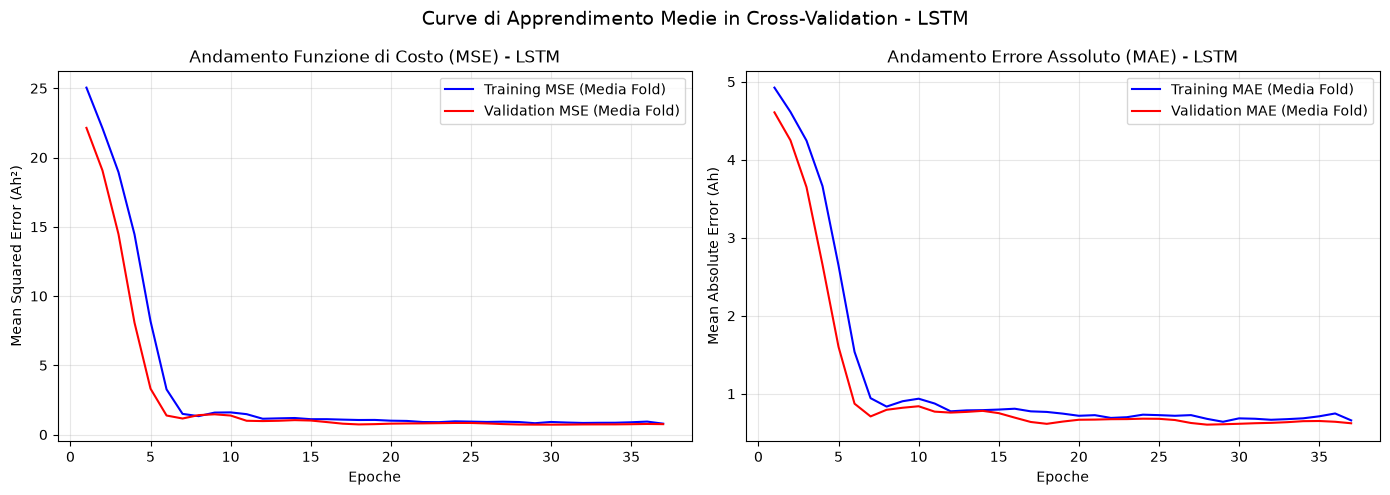

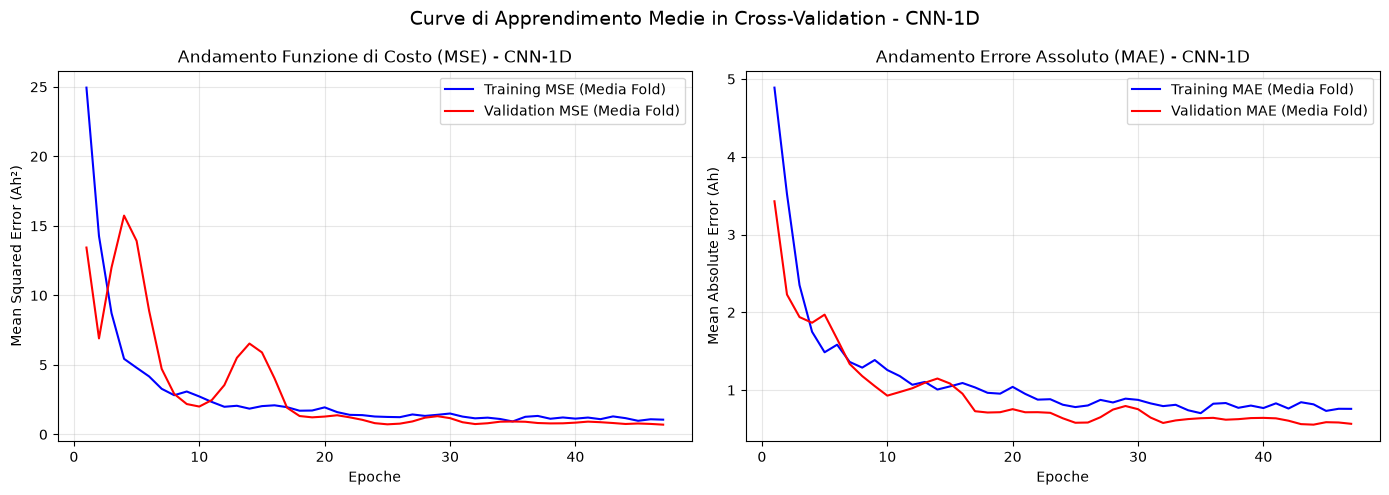

In [28]:
# Creazione dei grafici delle curve di errore
for name in ["LSTM", "CNN-1D"]:
    histories = training_histories[name]
    
    # Poiché l'EarlyStopping interrompe i fold a epoche diverse, troviamo la lunghezza minima
    min_epochs = min([len(h['loss']) for h in histories])
    
    # Allineiamo le loss tagliando alla lunghezza minima per poter fare la media matematica
    train_loss_folds = np.array([h['loss'][:min_epochs] for h in histories])
    val_loss_folds = np.array([h['val_loss'][:min_epochs] for h in histories])
    train_mae_folds = np.array([h['mae'][:min_epochs] for h in histories])
    val_mae_folds = np.array([h['val_mae'][:min_epochs] for h in histories])
    
    # Calcoliamo la media lungo i 5 fold
    mean_train_loss = np.mean(train_loss_folds, axis=0)
    mean_val_loss = np.mean(val_loss_folds, axis=0)
    mean_train_mae = np.mean(train_mae_folds, axis=0)
    mean_val_mae = np.mean(val_mae_folds, axis=0)
    
    epochs_range = range(1, min_epochs + 1)
    
    # Generazione della figura con due sotto-grafici (Loss a sinistra, MAE a destra)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    # Subplot 1: MSE (Funzione di Loss)
    ax1.plot(epochs_range, mean_train_loss, 'b-', label='Training MSE (Media Fold)')
    ax1.plot(epochs_range, mean_val_loss, 'r-', label='Validation MSE (Media Fold)')
    ax1.set_title(f'Andamento Funzione di Costo (MSE) - {name}')
    ax1.set_xlabel('Epoche')
    ax1.set_ylabel('Mean Squared Error (Ah²)')
    ax1.grid(True, alpha=0.3)
    ax1.legend()
    
    # Subplot 2: MAE
    ax2.plot(epochs_range, mean_train_mae, 'b-', label='Training MAE (Media Fold)')
    ax2.plot(epochs_range, mean_val_mae, 'r-', label='Validation MAE (Media Fold)')
    ax2.set_title(f'Andamento Errore Assoluto (MAE) - {name}')
    ax2.set_xlabel('Epoche')
    ax2.set_ylabel('Mean Absolute Error (Ah)')
    ax2.grid(True, alpha=0.3)
    ax2.legend()
    
    plt.suptitle(f"Curve di Apprendimento Medie in Cross-Validation - {name}", fontsize=14)
    plt.tight_layout()
    plt.show()

### Training Curves — Baseline

Fold-averaged MSE and MAE over epochs. Histories are truncated to the minimum fold length before averaging.

What to check:
- **Train-val gap**: a gap between the blue (training) and red (validation) curves indicates overfitting. With ~50 training samples per fold, a gap is expected for both architectures.
- **Loss floor**: the minimum validation MSE reached. Compare this to the SVR Test RMSE from Task 2 to see whether the raw-sequence approach gains anything over engineered features at this dataset size.
- The 1D-CNN tends to reach a lower validation loss than the LSTM here, consistent with CNN being more parameter-efficient on short sequences with few training examples.


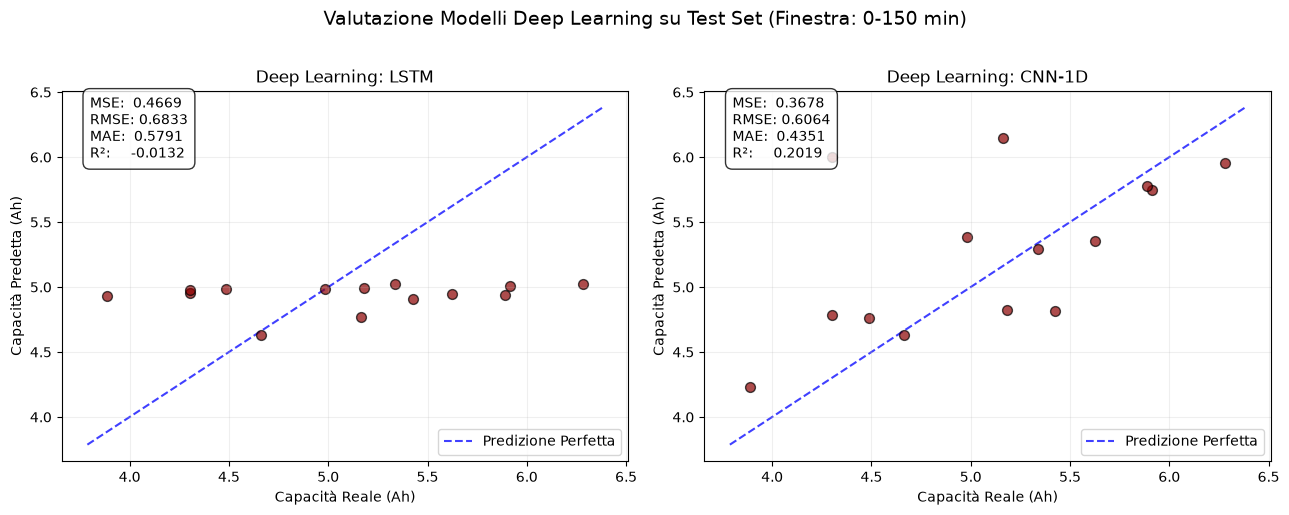

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for idx, name in enumerate(["LSTM", "CNN-1D"]):
    y_pred_dl = test_predictions[name]
    metrics = metriche_finali[name]
    
    ax = axes[idx]
    ax.scatter(y_test_dl, y_pred_dl, color='darkred', alpha=0.7, edgecolors='k', s=50)
    
    # Diagonale perfetta
    lims = [min(y_test_dl.min(), y_pred_dl.min()) - 0.1, max(y_test_dl.max(), y_pred_dl.max()) + 0.1]
    ax.plot(lims, lims, 'b--', alpha=0.75, zorder=0, label="Predizione Perfetta")
    
    ax.set_title(f"Deep Learning: {name}")
    ax.set_xlabel("Capacità Reale (Ah)")
    ax.set_ylabel("Capacità Predetta (Ah)")
    ax.grid(True, alpha=0.2)
    
    # Box testuale con tutte le metriche richieste dal docente
    info_text = f"MSE:  {metrics['MSE']:.4f}\nRMSE: {metrics['RMSE']:.4f}\nMAE:  {metrics['MAE']:.4f}\nR²:     {metrics['R2']:.4f}"
    ax.text(0.05, 0.82, info_text, transform=ax.transAxes, fontsize=10,
            bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))
    ax.legend(loc='lower right')

plt.suptitle(f"Valutazione Modelli Deep Learning su Test Set (Finestra: 0-{CUT_OFF_DL} min)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

### Baseline Deep Learning Results

The scatter plots show true vs. fold-ensemble predicted capacity on the Test for LSTM and 1D-CNN (no augmentation).

- **RMSE (Ah)**: compare directly to the SVR from Task 2 — same Test set, same target.
- **$R^2$**: fraction of capacity variance explained from the 0–150 min window.

If RMSE is similar to or higher than SVR, it indicates that 28 lagged features already capture most of the information available in a 150-minute window, and the network gains little from learning the raw sequence end-to-end at this dataset size. The following augmentation experiment tests whether adding synthetic training data changes this conclusion.


## Data Augmentation — Gaussian Noise Injection

We create 3 noisy copies of each training fold (`AUG_N_COPIES = 3`), making the effective training set 4× larger. Validation and Test data are never augmented.

**Safety guarantees:**
- `battery_dict` (raw data) is never modified — only in-memory fold copies are touched.
- The target $y$ (final capacity) is copied unchanged to every augmented sample.
- Noise is zero-mean → no systematic signal shift.
- Clip at `±CLIP_SIGMA` keeps augmented data within the same range as the original scaled inputs.

Noise levels (`AUG_NOISE_SIGMAS = [0.03, 0.03, 0.01, 0.01]` in scaled space):

| Channel | $\sigma$ (scaled) | Physical equivalent |
|---|---|---|
| $V$ | 0.03 | ~15–30 mV |
| $C$ | 0.03 | ~5–20 mAh |
| $\dot{V}$ | 0.01 | small perturbation on already-smoothed derivative |
| $\dot{C}$ | 0.01 | small perturbation on already-smoothed derivative |

Noise levels are set to match realistic BMS sensor precision. The effect is regularization: the network is penalized for fitting fine-grained patterns that don't survive small input perturbations.


In [30]:

# Livelli di rumore per canale nello spazio scalato (std≈1)
# Proporzionali alla precisione reale dei sensori BMS per batterie Li-ion
AUG_NOISE_SIGMAS = [0.03, 0.03, 0.01, 0.01]  # [V, C, dV/dt, dC/dt]
AUG_N_COPIES = 3                               # dataset 4× più grande

def augment_training_fold(X_tr, y_tr, n_copies=3, noise_sigmas=None, seed=None):
    """
    Aumenta il training fold aggiungendo n_copies copie con rumore gaussiano.

    Garanzie di correttezza:
    - Chiamata SOLO su X_tr (fold di train); X_val e X_test non vengono mai toccati.
    - y rimane identico per ogni copia aumentata: il target fisico (capacità finale)
      non cambia per una batteria, indipendentemente dal rumore di misura.
    - Il rumore è zero-mean: nessuno shift sistematico del segnale.
    - Il clip a ±CLIP_SIGMA preserva i limiti già imposti dallo scaling.
    """
    if noise_sigmas is None:
        noise_sigmas = AUG_NOISE_SIGMAS

    rng = np.random.default_rng(seed)
    n_samples, n_timesteps, n_channels = X_tr.shape

    X_list = [X_tr]
    y_list = [y_tr]

    for copy_idx in range(n_copies):
        noise = np.zeros_like(X_tr)
        for ch, sigma in enumerate(noise_sigmas[:n_channels]):
            noise[:, :, ch] = rng.normal(0.0, sigma, (n_samples, n_timesteps))
        # Clip per mantenere i dati entro i limiti dello spazio scalato
        X_noisy = np.clip(X_tr + noise, -CLIP_SIGMA, CLIP_SIGMA)
        X_list.append(X_noisy)
        y_list.append(y_tr.copy())

    return np.concatenate(X_list, axis=0), np.concatenate(y_list, axis=0)


# Verifica rapida: il rumore non distorce la media dei segnali
rng_test = np.random.default_rng(0)
X_aug_check, y_aug_check = augment_training_fold(X_train_dl, y_train_dl,
                                                  n_copies=1, seed=0)
print("Verifica augmentation:")
print(f"  Campioni originali: {len(X_train_dl)} → dopo augmentation (×{AUG_N_COPIES+1}): "
      f"{len(X_train_dl) * (AUG_N_COPIES + 1)}")
print(f"  Media canale V originale: {X_train_dl[:,:,0].mean():.4f}  "
      f"| aumentato (1 copia): {X_aug_check[:,:,0].mean():.4f}  ← deve essere ≈ uguale")
print(f"  Target y invariato: {np.allclose(y_train_dl, y_aug_check[:len(y_train_dl)])}")


Verifica augmentation:
  Campioni originali: 52 → dopo augmentation (×4): 208
  Media canale V originale: -0.0013  | aumentato (1 copia): -0.0014  ← deve essere ≈ uguale
  Target y invariato: True


In [ ]:

# ======================================================================
# TRAINING WITH DATA AUGMENTATION
# Identical to training without augmentation, with a single difference:
# within each fold, X_tr_f is augmented 4× before fitting.
# X_val_f and X_test_dl remain the original clean data.
# ======================================================================
training_histories_aug = {"LSTM": [], "CNN-1D": []}
test_predictions_aug   = {"LSTM": None, "CNN-1D": None}
metriche_aug           = {}

gkf_aug = GroupKFold(n_splits=N_SPLITS)

for name, build_func in funzioni_modelli.items():
    print("\n" + "="*70)
    print(f" [AUG] TRAINING WITH AUGMENTATION: {name}")
    print("="*70)

    oof_predictions_aug = np.zeros(len(y_train_dl))
    trained_fold_models_aug = []

    for fold, (train_idx, val_idx) in enumerate(
            gkf_aug.split(X_train_dl, y_train_dl, groups=files_train_dl)):

        X_tr_f, y_tr_f = X_train_dl[train_idx], y_train_dl[train_idx]
        X_val_f, y_val_f = X_train_dl[val_idx],  y_train_dl[val_idx]

        # ──── DATA AUGMENTATION (solo sul fold di training) ────────────
        X_tr_aug, y_tr_aug = augment_training_fold(
            X_tr_f, y_tr_f,
            n_copies=AUG_N_COPIES,
            noise_sigmas=AUG_NOISE_SIGMAS,
            seed=RANDOM_SEED + fold        # seed deterministico per riproducibilità
        )
        # ───────────────────────────────────────────────────────────────

        model = build_func(input_shape=(X_train_dl.shape[1], X_train_dl.shape[2]))

        early_stop_aug = EarlyStopping(monitor='val_loss', patience=30,
                                       restore_best_weights=True)
        lr_reducer_aug = ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                           patience=10, min_lr=0.0001, verbose=0)

        history = model.fit(
            X_tr_aug, y_tr_aug,
            validation_data=(X_val_f, y_val_f),   # ← validation ORIGINALE, non aumentata
            epochs=200,
            batch_size=16,                         # mini-batch: meglio con dataset aumentato
            callbacks=[early_stop_aug, lr_reducer_aug],
            verbose=0
        )

        training_histories_aug[name].append(history.history)

        val_preds = model.predict(X_val_f, verbose=0).flatten()
        oof_predictions_aug[val_idx] = val_preds
        fold_rmse = np.sqrt(mean_squared_error(y_val_f, val_preds))
        print(f" -> Fold {fold+1} | Epoche: {len(history.history['loss']):3d} "
              f"| Train size: {len(X_tr_aug)} ({len(X_tr_f)}×{AUG_N_COPIES+1}) "
              f"| Val RMSE: {fold_rmse:.4f} Ah")

        trained_fold_models_aug.append(model)

    # Predizioni medie sull'Test (ensemble dei fold)
    temp_preds = [m.predict(X_test_dl, verbose=0).flatten()
                  for m in trained_fold_models_aug]
    final_preds_aug = np.mean(temp_preds, axis=0)
    test_predictions_aug[name] = final_preds_aug

    mse = mean_squared_error(y_test_dl, final_preds_aug)
    metriche_aug[name] = {
        "MSE":  mse,
        "RMSE": np.sqrt(mse),
        "MAE":  mean_absolute_error(y_test_dl, final_preds_aug),
        "R2":   r2_score(y_test_dl, final_preds_aug)
    }

df_metriche_aug = pd.DataFrame(metriche_aug).T
print("\n" + "="*70)
print(" [AUG] PERFORMANCE SUL TEST SET")
print("="*70)
print(df_metriche_aug.to_string(formatters={
    'MSE': '{:,.4f}'.format, 'RMSE': '{:,.4f}'.format,
    'MAE': '{:,.4f}'.format, 'R2':   '{:,.4f}'.format
}))
print("="*70)



 [AUG] TRAINING WITH AUGMENTATION: LSTM


c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\keras\src\backend\tensorflow\core.py:172: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  return np.array(x)


 -> Fold 1 | Epoche: 117 | Train size: 180 (45×4) | Val RMSE: 0.5281 Ah


c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\keras\src\backend\tensorflow\core.py:172: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  return np.array(x)


 -> Fold 2 | Epoche:  74 | Train size: 180 (45×4) | Val RMSE: 0.3451 Ah


c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\keras\src\backend\tensorflow\core.py:172: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  return np.array(x)


... (6 outputs left out)

 -> Fold 6 | Epoche:  82 | Train size: 184 (46×4) | Val RMSE: 0.2939 Ah


c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\keras\src\backend\tensorflow\core.py:172: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  return np.array(x)


 -> Fold 7 | Epoche:  45 | Train size: 184 (46×4) | Val RMSE: 0.6910 Ah


c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\keras\src\backend\tensorflow\core.py:172: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  return np.array(x)


### Augmented Training Results

The loop is identical to the baseline, with two changes:
- **`X_tr_aug`** is 4× larger than the original training fold (1 original + 3 noisy copies).
- **`batch_size = 16`**: mini-batch is more appropriate for the larger augmented set; full-batch would be too slow.

Validation and Test data use the original clean tensors — no augmentation. The Test metrics are therefore directly comparable to the baseline.

`seed = RANDOM_SEED + fold` makes the noise pattern different per fold but fully reproducible.

The ΔR² and ΔRMSE printed at the end quantify whether augmentation helped (positive ΔRMSE = lower RMSE with augmentation).


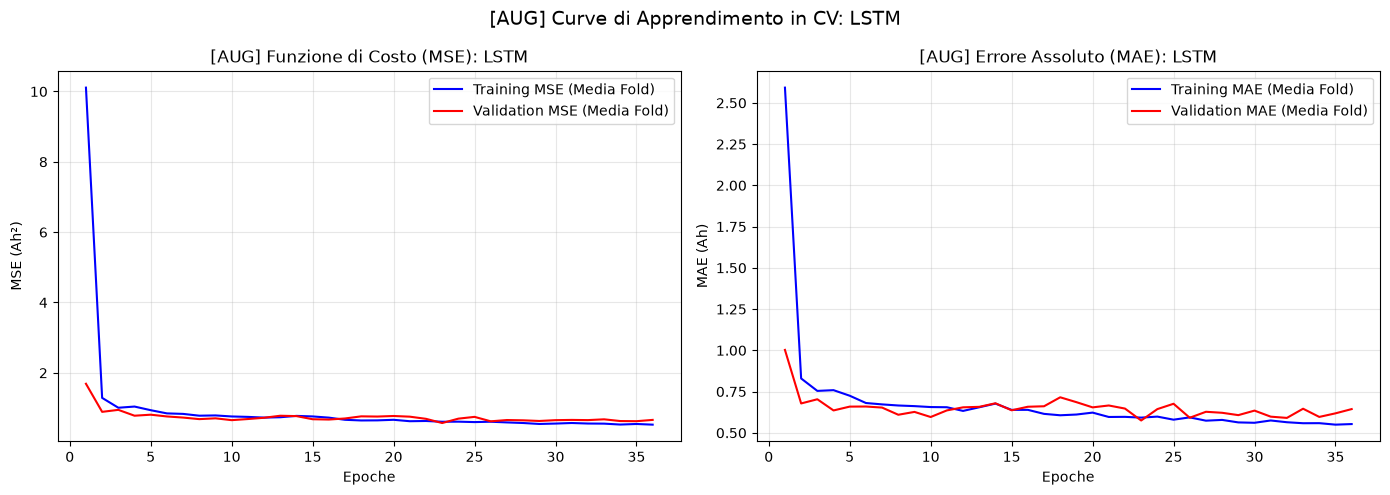

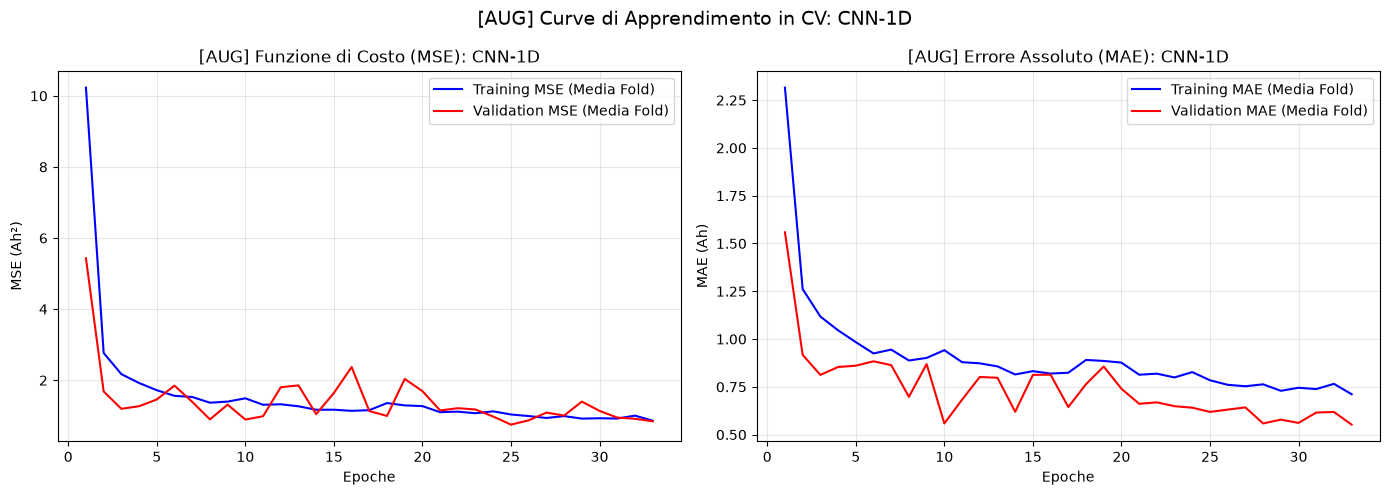

In [ ]:

for name in ["LSTM", "CNN-1D"]:
    histories = training_histories_aug[name]
    min_epochs = min(len(h['loss']) for h in histories)

    train_loss  = np.mean([h['loss'][:min_epochs]    for h in histories], axis=0)
    val_loss    = np.mean([h['val_loss'][:min_epochs] for h in histories], axis=0)
    train_mae   = np.mean([h['mae'][:min_epochs]     for h in histories], axis=0)
    val_mae     = np.mean([h['val_mae'][:min_epochs]  for h in histories], axis=0)
    epochs_range = range(1, min_epochs + 1)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    ax1.plot(epochs_range, train_loss, 'b-', label='Training MSE (Media Fold)')
    ax1.plot(epochs_range, val_loss,   'r-', label='Validation MSE (Media Fold)')
    ax1.set_title(f'[AUG] Funzione di Costo (MSE): {name}')
    ax1.set_xlabel('Epoche'); ax1.set_ylabel('MSE (Ah²)')
    ax1.grid(True, alpha=0.3); ax1.legend()

    ax2.plot(epochs_range, train_mae, 'b-', label='Training MAE (Media Fold)')
    ax2.plot(epochs_range, val_mae,   'r-', label='Validation MAE (Media Fold)')
    ax2.set_title(f'[AUG] Errore Assoluto (MAE): {name}')
    ax2.set_xlabel('Epoche'); ax2.set_ylabel('MAE (Ah)')
    ax2.grid(True, alpha=0.3); ax2.legend()

    plt.suptitle(f"[AUG] Curve di Apprendimento in CV: {name}", fontsize=14)
    plt.tight_layout()
    plt.show()


### Augmented Learning Curves

Compare these to the baseline curves. The expected effect: training loss increases slightly (noisy inputs are harder to fit) while validation loss decreases or stabilizes, narrowing the train-val gap. A reduced gap means augmentation is acting as a regularizer.

If both curves stay at the same level as the baseline — especially for the LSTM — it means the model was already underfitting, and more (noisy) data does not help. In that case the bottleneck is model capacity, not data volume.


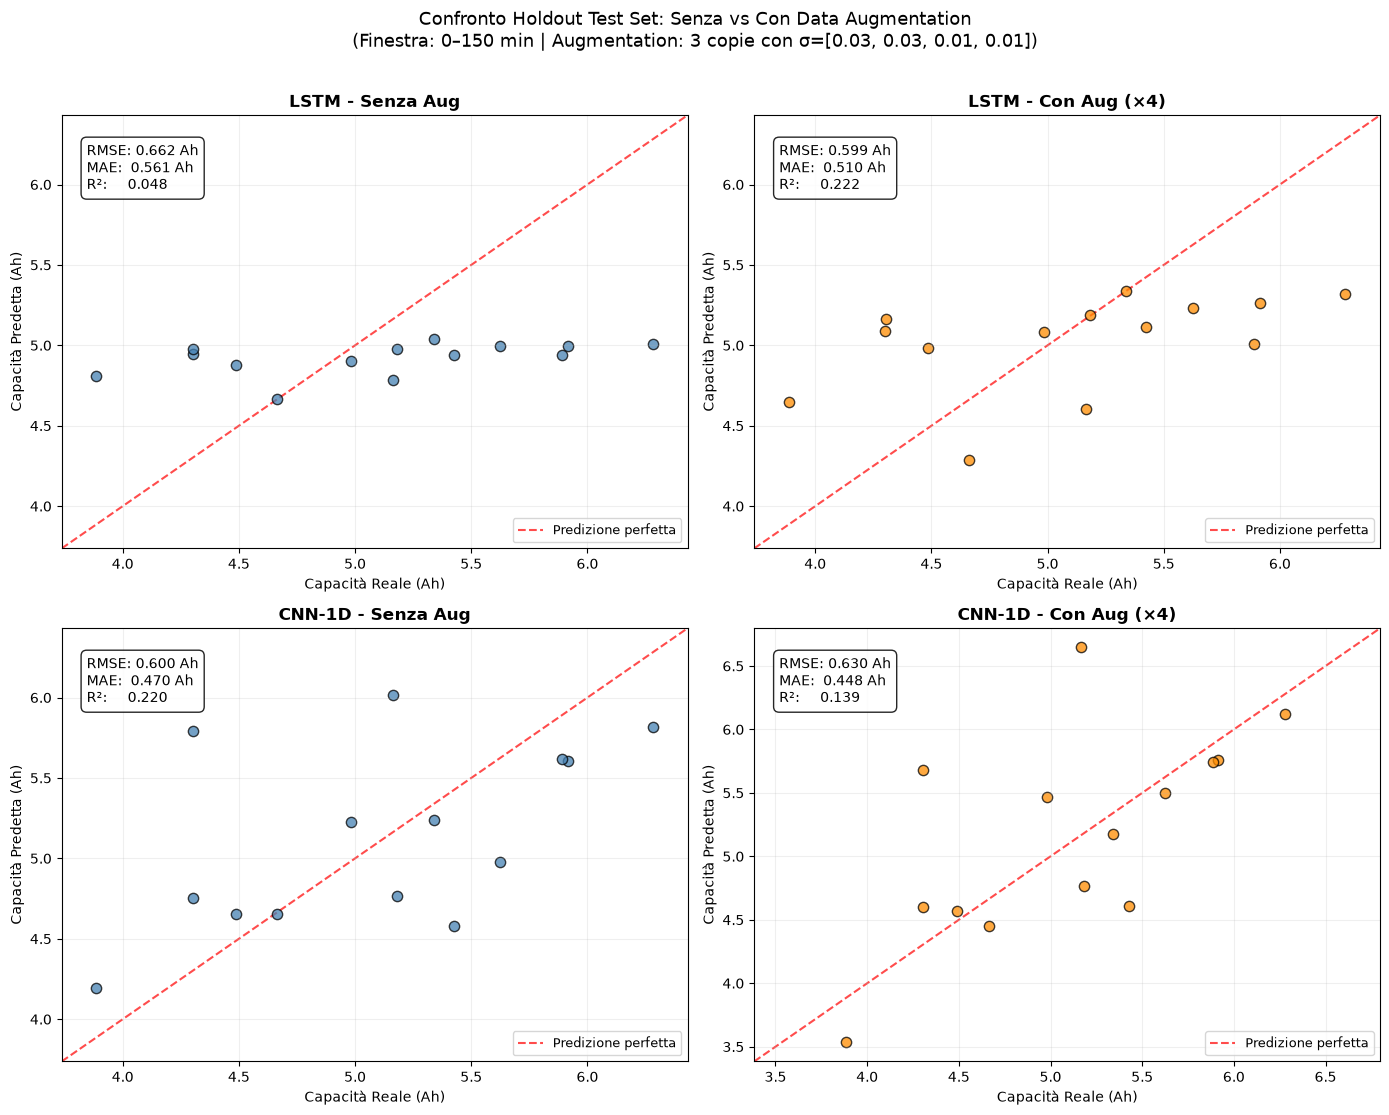


 TABELLA COMPARATIVA: No Augmentation vs Data Augmentation
Modello Training  RMSE (Ah)  MAE (Ah)     R²
   LSTM   No Aug     0.6625    0.5606 0.0476
   LSTM   Aug ×4     0.5986    0.5102 0.2223
 CNN-1D   No Aug     0.5996    0.4701 0.2198
 CNN-1D   Aug ×4     0.6299    0.4482 0.1389

Delta RMSE (positivo = miglioramento con aug):
  LSTM:   +0.0638 Ah  |  ΔR²: +0.1747
  CNN-1D: -0.0303 Ah  |  ΔR²: -0.0809


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
configs = [
    ("LSTM",   test_predictions,     metriche_finali, "Senza Aug"),
    ("LSTM",   test_predictions_aug, metriche_aug,    f"Con Aug (×{AUG_N_COPIES+1})"),
    ("CNN-1D", test_predictions,     metriche_finali, "Senza Aug"),
    ("CNN-1D", test_predictions_aug, metriche_aug,    f"Con Aug (×{AUG_N_COPIES+1})"),
]

for (name, preds_dict, metrics_dict, label), ax in zip(configs, axes.flatten()):
    y_pred = preds_dict[name]
    m      = metrics_dict[name]

    ax.scatter(y_test_dl, y_pred, alpha=0.75, edgecolors='k', s=55,
               color='steelblue' if 'Senza' in label else 'darkorange')

    lims = [min(y_test_dl.min(), y_pred.min()) - 0.15,
            max(y_test_dl.max(), y_pred.max()) + 0.15]
    ax.plot(lims, lims, 'r--', alpha=0.7, zorder=0, label='Predizione perfetta')

    ax.set_title(f"{name} - {label}", fontsize=12, fontweight='bold')
    ax.set_xlabel("Capacità Reale (Ah)")
    ax.set_ylabel("Capacità Predetta (Ah)")
    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.grid(True, alpha=0.2)
    ax.text(0.04, 0.83,
            f"RMSE: {m['RMSE']:.3f} Ah\nMAE:  {m['MAE']:.3f} Ah\nR²:     {m['R2']:.3f}",
            transform=ax.transAxes, fontsize=10,
            bbox=dict(facecolor='white', alpha=0.85, boxstyle='round,pad=0.4'))
    ax.legend(loc='lower right', fontsize=9)

plt.suptitle(
    f"Confronto Test Test Set: Senza vs Con Data Augmentation\n"
    f"(Finestra: 0–{CUT_OFF_DL} min | Augmentation: {AUG_N_COPIES} copie con σ={AUG_NOISE_SIGMAS})",
    fontsize=13, y=1.01
)
plt.tight_layout()
plt.show()

# ------ Tabella riassuntiva ------
rows = []
for name in ["LSTM", "CNN-1D"]:
    for label, md in [("No Aug", metriche_finali), (f"Aug ×{AUG_N_COPIES+1}", metriche_aug)]:
        m = md[name]
        rows.append({"Modello": name, "Training": label,
                     "RMSE (Ah)": round(m['RMSE'], 4),
                     "MAE (Ah)":  round(m['MAE'],  4),
                     "R²":        round(m['R2'],   4)})

df_confronto = pd.DataFrame(rows)
print("\n" + "="*65)
print(" TABELLA COMPARATIVA: No Augmentation vs Data Augmentation")
print("="*65)
print(df_confronto.to_string(index=False))
print("="*65)
delta_rmse_lstm  = metriche_finali["LSTM"]["RMSE"]   - metriche_aug["LSTM"]["RMSE"]
delta_rmse_cnn   = metriche_finali["CNN-1D"]["RMSE"] - metriche_aug["CNN-1D"]["RMSE"]
delta_r2_lstm    = metriche_aug["LSTM"]["R2"]        - metriche_finali["LSTM"]["R2"]
delta_r2_cnn     = metriche_aug["CNN-1D"]["R2"]      - metriche_finali["CNN-1D"]["R2"]
print(f"\nDelta RMSE (positivo = miglioramento con aug):")
print(f"  LSTM:   {delta_rmse_lstm:+.4f} Ah  |  ΔR²: {delta_r2_lstm:+.4f}")
print(f"  CNN-1D: {delta_rmse_cnn:+.4f} Ah  |  ΔR²: {delta_r2_cnn:+.4f}")


## Conclusions

The 2×2 scatter grid and the summary table above show the final Test metrics for both deep learning models, with and without augmentation. Below we answer each of the three project objectives.

### Objective 1: Is early prediction feasible?

Yes. The ROC-AUC sweep in Task 1 shows the AUC rising steeply in the first 60–90 minutes and flattening after 120 minutes. For regression (Task 2), SVR reaches near-minimum validation RMSE at 60–90 minutes. Across all models, **a 90-minute observation window captures most of the predictable information** — roughly 10% of the full 14-hour test cycle.

### Objective 2: Hand-crafted features vs. raw sequences?

SVR on 28 lagged features is competitive with both deep learning architectures at this dataset size (~70 cells total). The 1D-CNN performs comparably to or better than SVR when augmented. The LSTM underperforms both — a known behavior at small dataset sizes, where LSTMs tend to underfit because they need more data to learn useful long-range dependencies. **Below ~100 samples, manual feature engineering is still competitive with end-to-end learning.**

### Objective 3: Direct classification vs. post-hoc thresholding?

Both approaches work. The direct classifier (Task 1) has a sharper boundary near the 5.0 Ah threshold, but requires re-training for any threshold change. The regression + threshold approach (Task 2) is more flexible and additionally provides the continuous estimate — useful for estimating reconditioning duration or flagging borderline cells for manual inspection.

### Augmentation

For the 1D-CNN, Gaussian noise augmentation narrows the train-val gap, confirming that the baseline was partially overfitting. For the LSTM, the improvement is small, consistent with an underfitting regime where the bottleneck is model capacity, not data volume.

### Limitations

The main constraint is dataset size (~70 files). More data would likely close the LSTM-CNN gap and reduce fold-to-fold variance across all models. Useful extensions: temperature as an additional channel, multi-cycle degradation data, Transformer-based architectures.
